In [ ]:
from google.colab import drive

drive.mount('/content/drive')
base = "/content/drive/MyDrive/UTokyo/Proteome/"

Mounted at /content/drive


# SP+/SP- Orthogroup Tagging

In [ ]:
# ============================================================
# SP+/SP- Orthogroup Tagging
# Joins OrthoFinder Orthogroups.tsv against per-strain secretome
# tables (09_final/) to tag each orthogroup with SP+/SP-/other
# membership per strain.
# ============================================================

import pandas as pd
import re
import os

# --- CONFIG: adjust paths to match your actual Drive layout ---
base = "/content/drive/MyDrive/UTokyo/Proteome/"
SECRETOME_ROOT = os.path.join(base, "Prediction_vs_Detection")
ORTHO_ROOT = os.path.join(base, "9_Ortholog_analysis")
ORTHOGROUPS_TSV = os.path.join(ORTHO_ROOT, "Pro_OF_dendroblast", "Orthogroups", "Orthogroups.tsv")
OUTPUT_DIR = os.path.join(base, "Publication", "data_pre")

# 7-strain set, matching OrthoFinder species naming exactly
STRAINS = ["Spil", "Snat", "Stri", "Slin", "Snec", "Smic_jgi", "Bmin"]

# ============================================================
# STEP 1: Load Orthogroups.tsv
# ============================================================
og = pd.read_csv(ORTHOGROUPS_TSV, sep="\t")
print(f"[CHECK] Orthogroups.tsv loaded: {og.shape[0]} orthogroups, columns: {list(og.columns)}")

missing_strains = [s for s in STRAINS if s not in og.columns]
if missing_strains:
    print(f"[WARNING] Strains not found as columns in Orthogroups.tsv: {missing_strains}")
    print(f"          Actual columns are: {list(og.columns)}")
    print(f"          -> Update STRAINS list above to match exactly before proceeding.")

# ============================================================
# STEP 2: Melt to long format (one row per gene per orthogroup)
# ============================================================
long_rows = []
for _, row in og.iterrows():
    orthogroup = row["Orthogroup"]
    for strain in STRAINS:
        if strain not in og.columns:
            continue
        cell = row[strain]
        if pd.isna(cell):
            continue
        # Orthogroups.tsv cells can contain multiple comma-separated gene IDs
        gene_ids = [g.strip() for g in str(cell).split(",") if g.strip()]
        for gid in gene_ids:
            long_rows.append({"orthogroup": orthogroup, "strain": strain, "gene_id": gid})

og_long = pd.DataFrame(long_rows)
print(f"[CHECK] Long-format orthogroup membership table: {og_long.shape[0]} gene-orthogroup rows")
print(og_long.groupby("strain").size())

# ============================================================
# STEP 3: ID normalization (reuse established per-strain logic)
# ============================================================
BMIN_PATTERN = re.compile(r"(symbB\.v1\.2\.\d{6}\.t\d+)")

def normalize_id(strain, gene_id):
    """Normalize a gene ID to a strain-appropriate join key."""
    if strain == "Bmin":
        m = BMIN_PATTERN.search(gene_id)
        return m.group(1) if m else gene_id
    elif strain == "Smic_jgi":
        # jgi_ prefix: replace first 3 underscores with pipes to match
        # secretome pipeline header convention
        parts = gene_id.split("_", 3)
        if len(parts) == 4:
            return "|".join(parts[:3]) + "_" + parts[3]
        return gene_id
    else:
        # Snat and others: matched directly on existing accession (e.g. CAE)
        return gene_id

og_long["join_key"] = og_long.apply(lambda r: normalize_id(r["strain"], r["gene_id"]), axis=1)

# ============================================================
# STEP 4: Parse SP+/SP- FASTA headers per strain
# ============================================================
def parse_fasta_headers(filepath):
    """Return a set of header IDs (first whitespace-delimited token, minus '>')."""
    headers = set()
    if not os.path.exists(filepath):
        return headers
    with open(filepath) as f:
        for line in f:
            if line.startswith(">"):
                header = line[1:].strip().split()[0]
                headers.add(header)
    return headers

secretome_membership = {}  # (strain, join_key) -> "SP+" or "SP-"

for strain in STRAINS:
    sp_pos_path = os.path.join(SECRETOME_ROOT, strain, "09_final", f"{strain}_SP_pos_secretome_final.faa")
    sp_neg_path = os.path.join(SECRETOME_ROOT, strain, "09_final", f"{strain}_SP_neg_secretome_final.faa")

    sp_pos_ids = parse_fasta_headers(sp_pos_path)
    sp_neg_ids = parse_fasta_headers(sp_neg_path)

    print(f"[CHECK] {strain}: SP+ file {'FOUND' if os.path.exists(sp_pos_path) else 'MISSING'} "
          f"({len(sp_pos_ids)} seqs) | SP- file {'FOUND' if os.path.exists(sp_neg_path) else 'MISSING'} "
          f"({len(sp_neg_ids)} seqs)")

    for gid in sp_pos_ids:
        key = normalize_id(strain, gid)
        secretome_membership[(strain, key)] = "SP+"
    for gid in sp_neg_ids:
        key = normalize_id(strain, gid)
        secretome_membership[(strain, key)] = "SP-"

# ============================================================
# STEP 5: Tag orthogroup membership table with secretome category
# ============================================================
og_long["secretome_category"] = og_long.apply(
    lambda r: secretome_membership.get((r["strain"], r["join_key"]), "not_secreted"),
    axis=1
)

# --- Validation: match rate check ---
matched = (og_long["secretome_category"] != "not_secreted").sum()
total_secretome_genes = len(secretome_membership)
print(f"\n[VALIDATION] {matched} / {total_secretome_genes} secretome genes matched to an orthogroup "
      f"({100*matched/total_secretome_genes:.1f}% coverage)" if total_secretome_genes else "[VALIDATION] No secretome genes loaded - check paths above.")

if total_secretome_genes and matched / total_secretome_genes < 0.8:
    print("[WARNING] Match rate below 80% - check ID normalization or file paths before trusting downstream results.")

# ============================================================
# STEP 6: Pivot to wide per-orthogroup-per-strain summary
# ============================================================
pivot = og_long.pivot_table(
    index="orthogroup",
    columns="strain",
    values="secretome_category",
    aggfunc=lambda x: ";".join(sorted(set(x)))  # flags if a strain has mixed SP+/SP- paralogs in one OG
).reindex(columns=STRAINS)

pivot = pivot.fillna("absent")
pivot = pivot.reset_index()

print(f"\n[CHECK] Final tagged orthogroup table: {pivot.shape[0]} orthogroups x {len(STRAINS)} strains")
print(pivot.head())

# ============================================================
# STEP 7: Save outputs
# ============================================================
os.makedirs(OUTPUT_DIR, exist_ok=True)

long_out = os.path.join(OUTPUT_DIR, "orthogroup_secretome_tagging_long.tsv")
wide_out = os.path.join(OUTPUT_DIR, "orthogroup_secretome_tagging_wide.tsv")

og_long.to_csv(long_out, sep="\t", index=False)
pivot.to_csv(wide_out, sep="\t", index=False)

print(f"\n[SAVED] Long format: {long_out}")
print(f"[SAVED] Wide format: {wide_out}")

[CHECK] Orthogroups.tsv loaded: 30844 orthogroups, columns: ['Orthogroup', 'Bmin', 'Slin', 'Smic_jgi', 'Snat', 'Snec', 'Spil', 'Stri']
[CHECK] Long-format orthogroup membership table: 225624 gene-orthogroup rows
strain
Bmin        36917
Slin        29277
Smic_jgi    36514
Snat        30496
Snec        32845
Spil        20796
Stri        38779
dtype: int64
[CHECK] Spil: SP+ file FOUND (406 seqs) | SP- file FOUND (115 seqs)
[CHECK] Snat: SP+ file FOUND (983 seqs) | SP- file FOUND (274 seqs)
[CHECK] Stri: SP+ file FOUND (1066 seqs) | SP- file FOUND (277 seqs)
[CHECK] Slin: SP+ file FOUND (807 seqs) | SP- file FOUND (191 seqs)
[CHECK] Snec: SP+ file FOUND (782 seqs) | SP- file FOUND (199 seqs)
[CHECK] Smic_jgi: SP+ file FOUND (599 seqs) | SP- file FOUND (192 seqs)
[CHECK] Bmin: SP+ file FOUND (752 seqs) | SP- file FOUND (232 seqs)

[VALIDATION] 6245 / 6875 secretome genes matched to an orthogroup (90.8% coverage)

[CHECK] Final tagged orthogroup table: 30844 orthogroups x 7 strains
strain 

**90.8% of secretome proteins matched the orthogroups.**

In [ ]:
# ============================================================
# Confirm remaining unmatched secretome genes are genuine
# singletons (present in Orthogroups_UnassignedGenes.tsv),
# not a leftover normalization bug.
# ============================================================

UNASSIGNED_TSV = os.path.join(ORTHO_ROOT, "Pro_OF_dendroblast", "Orthogroups", "Orthogroups_UnassignedGenes.tsv")
unassigned = pd.read_csv(UNASSIGNED_TSV, sep="\t")
print(f"[CHECK] Unassigned genes file loaded: {unassigned.shape[0]} singleton genes")

# Build the same long-format unassigned gene set, normalized the same way
unassigned_keys = set()
for _, row in unassigned.iterrows():
    for strain in STRAINS:
        if strain not in unassigned.columns:
            continue
        cell = row[strain]
        if pd.isna(cell):
            continue
        for gid in str(cell).split(","):
            gid = gid.strip()
            if gid:
                unassigned_keys.add((strain, normalize_id(strain, gid)))

# Find secretome genes that matched neither Orthogroups.tsv nor unassigned list
all_secretome_keys = set(secretome_membership.keys())
matched_keys = set(zip(og_long["strain"], og_long["join_key"])) & all_secretome_keys
truly_unexplained = all_secretome_keys - matched_keys - unassigned_keys

print(f"[CHECK] Total secretome genes: {len(all_secretome_keys)}")
print(f"[CHECK] Matched to an orthogroup: {len(matched_keys)}")
print(f"[CHECK] Confirmed singletons (in Orthogroups_UnassignedGenes.tsv): "
      f"{len(all_secretome_keys & unassigned_keys)}")
print(f"[CHECK] Truly unexplained (neither orthogroup nor singleton list): {len(truly_unexplained)}")

if truly_unexplained:
    print("\nSample unexplained IDs (worth investigating further):")
    for strain, key in list(truly_unexplained)[:10]:
        print(f"    {strain}: {key}")
else:
    print("\n[OK] Every secretome gene is accounted for - either orthogroup-matched or a confirmed singleton.")

[CHECK] Unassigned genes file loaded: 29507 singleton genes
[CHECK] Total secretome genes: 6875
[CHECK] Matched to an orthogroup: 6245
[CHECK] Confirmed singletons (in Orthogroups_UnassignedGenes.tsv): 630
[CHECK] Truly unexplained (neither orthogroup nor singleton list): 0

[OK] Every secretome gene is accounted for - either orthogroup-matched or a confirmed singleton.


# Recompute orthogroups from `Orthogroups.tsv`

In [ ]:
# ============================================================
# Recompute opening-paragraph orthogroup statistics directly from
# Orthogroups.tsv - the SAME file Panels A/B/C and the SP+/SP-
# tagging table are built from - instead of Statistics_Overall.tsv,
# which appears to use a different counting convention.
# ============================================================

import os
import pandas as pd

ORTHO_ROOT = os.path.join(base, "9_Ortholog_analysis")
ORTHOGROUPS_TSV = os.path.join(ORTHO_ROOT, "Pro_OF_dendroblast", "Orthogroups", "Orthogroups.tsv")

og = pd.read_csv(ORTHOGROUPS_TSV, sep="\t")
STRAINS = ["Spil", "Snat", "Stri", "Slin", "Snec", "Smic_jgi", "Bmin"]

print(f"[CHECK] Total orthogroups: {og.shape[0]:,}")

# All seven strains present (at least one gene each)
present = og[STRAINS].notna()
all_seven = present.all(axis=1)
print(f"[CHECK] All seven strains present: {int(all_seven.sum()):,}")

# Single-copy: all seven present AND exactly one gene per strain (no comma)
def is_single_gene(cell):
    return pd.notna(cell) and "," not in str(cell)

single_copy_mask = og[STRAINS].map(is_single_gene).all(axis=1)
print(f"[CHECK] Single-copy orthogroups (all 7 strains, 1 gene each): {int(single_copy_mask.sum()):,}")

# Species-specific: exactly one strain column populated
n_strains_present = present.sum(axis=1)
species_specific = (n_strains_present == 1)
print(f"[CHECK] Species-specific orthogroups (only 1 strain present): {int(species_specific.sum()):,}")

[CHECK] Total orthogroups: 30,844
[CHECK] All seven strains present: 5,755
[CHECK] Single-copy orthogroups (all 7 strains, 1 gene each): 1,129
[CHECK] Species-specific orthogroups (only 1 strain present): 1,898


In [ ]:
import os
import pandas as pd

ORTHO_ROOT = os.path.join(
    base,
    "9_Ortholog_analysis",
    "Pro_OF_dendroblast",
)

HOG_TSV = os.path.join(
    ORTHO_ROOT,
    "WorkingDirectory",
    "N0.ids.tsv",
)

STRAINS = [
    "Spil",
    "Snat",
    "Stri",
    "Slin",
    "Snec",
    "Smic_jgi",
    "Bmin",
]

hog = pd.read_csv(HOG_TSV, sep="\t")

print("Columns:")
print(hog.columns.tolist())

missing = [s for s in STRAINS if s not in hog.columns]
if missing:
    raise KeyError(f"Missing strain columns: {missing}")


def count_genes(cell):
    if pd.isna(cell):
        return 0

    text = str(cell).strip()

    if not text:
        return 0

    return len([
        gene.strip()
        for gene in text.split(",")
        if gene.strip()
    ])


gene_counts = hog[STRAINS].map(count_genes)

# Match OrthoFinder's definition: groups containing at least
# two proteins are proper orthogroups.
proper = gene_counts.sum(axis=1).gt(1)

hog_proper = hog.loc[proper].copy()
counts_proper = gene_counts.loc[proper].copy()

present = counts_proper.gt(0)
n_species_present = present.sum(axis=1)

all_seven = n_species_present.eq(7)
species_specific = n_species_present.eq(1)
single_copy = counts_proper.eq(1).all(axis=1)

print(f"Root-level HOGs:              {len(hog_proper):,}")
print(f"All seven strains present:   {all_seven.sum():,}")
print(f"Single-copy HOGs:             {single_copy.sum():,}")
print(f"Strain-specific HOGs:         {species_specific.sum():,}")
print(
    f"Proteins assigned to HOGs:   "
    f"{counts_proper.to_numpy().sum():,}"
)

print("\nNumber of strains represented:")
print(
    n_species_present
    .value_counts()
    .sort_index()
    .rename_axis("Number of strains")
    .rename("Number of HOGs")
)

Columns:
['HOG', 'OG', 'Gene Tree Parent Clade', 'Bmin', 'Slin', 'Smic_jgi', 'Snat', 'Snec', 'Spil', 'Stri']
Root-level HOGs:              31,080
All seven strains present:   5,692
Single-copy HOGs:             1,138
Strain-specific HOGs:         1,900
Proteins assigned to HOGs:   225,537

Number of strains represented:
Number of strains
1    1900
2    5831
3    3980
4    4029
5    4412
6    5236
7    5692
Name: Number of HOGs, dtype: int64


In [ ]:
import os
import pandas as pd

ORTHOGROUPS_TSV = os.path.join(
    base,
    "9_Ortholog_analysis",
    "Pro_OF_dendroblast",
    "Orthogroups",
    "Orthogroups.tsv",
)

UNASSIGNED_TSV = os.path.join(
    base,
    "9_Ortholog_analysis",
    "Pro_OF_dendroblast",
    "Orthogroups",
    "Orthogroups_UnassignedGenes.tsv",
)

STRAINS = [
    "Spil",
    "Snat",
    "Stri",
    "Slin",
    "Snec",
    "Smic_jgi",
    "Bmin",
]

og = pd.read_csv(ORTHOGROUPS_TSV, sep="\t")


def count_genes(cell):
    """Count comma-separated protein IDs in one Orthogroups.tsv cell."""
    if pd.isna(cell):
        return 0

    return len([
        protein_id.strip()
        for protein_id in str(cell).split(",")
        if protein_id.strip()
    ])


# Number of proteins from each strain in each orthogroup
gene_counts = og[STRAINS].map(count_genes)

# Presence/absence by strain
present = gene_counts.gt(0)
n_strains_present = present.sum(axis=1)

# Main orthogroup statistics
n_orthogroups = len(og)
n_assigned = int(gene_counts.to_numpy().sum())

all_seven = n_strains_present.eq(len(STRAINS))
single_copy = gene_counts.eq(1).all(axis=1)
strain_specific = n_strains_present.eq(1)

n_strain_specific_genes = int(
    gene_counts.loc[strain_specific].to_numpy().sum()
)

# Count unassigned proteins directly
unassigned = pd.read_csv(UNASSIGNED_TSV, sep="\t")

unassigned_counts = unassigned[STRAINS].map(count_genes)
n_unassigned = int(unassigned_counts.to_numpy().sum())

n_total = n_assigned + n_unassigned
pct_assigned = 100 * n_assigned / n_total
pct_unassigned = 100 * n_unassigned / n_total

pct_strain_specific_genes = (
    100 * n_strain_specific_genes / n_total
)

# Orthogroup distribution by number of represented strains
distribution = (
    n_strains_present
    .value_counts()
    .reindex(range(1, len(STRAINS) + 1), fill_value=0)
    .sort_index()
)

print("ORTHOGROUP SUMMARY")
print("------------------")
print(f"Total proteins:                         {n_total:,}")
print(f"Proteins assigned to orthogroups:       {n_assigned:,}")
print(f"Unassigned proteins:                    {n_unassigned:,}")
print(f"Percentage assigned:                    {pct_assigned:.1f}%")
print(f"Percentage unassigned:                  {pct_unassigned:.1f}%")
print()
print(f"Total orthogroups:                      {n_orthogroups:,}")
print(f"Strain-specific orthogroups:            {strain_specific.sum():,}")
print(f"Proteins in strain-specific OGs:        {n_strain_specific_genes:,}")
print(
    f"Percentage in strain-specific OGs:      "
    f"{pct_strain_specific_genes:.1f}%"
)
print(f"All-seven-strain orthogroups:           {all_seven.sum():,}")
print(f"Single-copy orthogroups:                {single_copy.sum():,}")

print("\nNUMBER OF STRAINS REPRESENTED")
print("-----------------------------")
for n_strains, n_groups in distribution.items():
    print(f"{n_strains} strain(s): {n_groups:,} orthogroups")

print(
    "\nDistribution total:",
    f"{distribution.sum():,}",
)

ORTHOGROUP SUMMARY
------------------
Total proteins:                         255,131
Proteins assigned to orthogroups:       225,624
Unassigned proteins:                    29,507
Percentage assigned:                    88.4%
Percentage unassigned:                  11.6%

Total orthogroups:                      30,844
Strain-specific orthogroups:            1,898
Proteins in strain-specific OGs:        5,881
Percentage in strain-specific OGs:      2.3%
All-seven-strain orthogroups:           5,755
Single-copy orthogroups:                1,129

NUMBER OF STRAINS REPRESENTED
-----------------------------
1 strain(s): 1,898 orthogroups
2 strain(s): 5,751 orthogroups
3 strain(s): 3,901 orthogroups
4 strain(s): 3,939 orthogroups
5 strain(s): 4,355 orthogroups
6 strain(s): 5,245 orthogroups
7 strain(s): 5,755 orthogroups

Distribution total: 30,844


# UpSet plot

In [ ]:
!pip install upsetplot -q

  Installing build dependencies ... done
  Getting requirements to build wheel ... done
  Preparing metadata (pyproject.toml) ... done



[SP_POS] 2531 orthogroups have at least one SP+ member (out of 30844 total orthogroups)
  (Plot below only displays intersections with >10 orthogroups; summary counts here are exact totals, unfiltered.)


/usr/local/lib/python3.12/dist-packages/upsetplot/plotting.py:795: FutureWarning: A value is trying to be set on a copy of a DataFrame or Series through chained assignment using an inplace method.
The behavior will change in pandas 3.0. This inplace method will never work because the intermediate object on which we are setting values always behaves as a copy.

For example, when doing 'df[col].method(value, inplace=True)', try using 'df.method({col: value}, inplace=True)' or df[col] = df[col].method(value) instead, to perform the operation inplace on the original object.


  styles["linewidth"].fillna(1, inplace=True)
/usr/local/lib/python3.12/dist-packages/upsetplot/plotting.py:796: FutureWarning: A value is trying to be set on a copy of a DataFrame or Series through chained assignment using an inplace method.
The behavior will change in pandas 3.0. This inplace method will never work because the intermediate object on which we are setting values always behaves as a copy.

For example,

[SAVED] /content/drive/MyDrive/UTokyo/Proteome/Publication/figures_pre/sp_pos_orthogroup_upset.pdf
[SAVED] /content/drive/MyDrive/UTokyo/Proteome/Publication/figures_pre/sp_pos_orthogroup_upset.svg
[SAVED] /content/drive/MyDrive/UTokyo/Proteome/Publication/figures_pre/sp_pos_orthogroup_upset.png


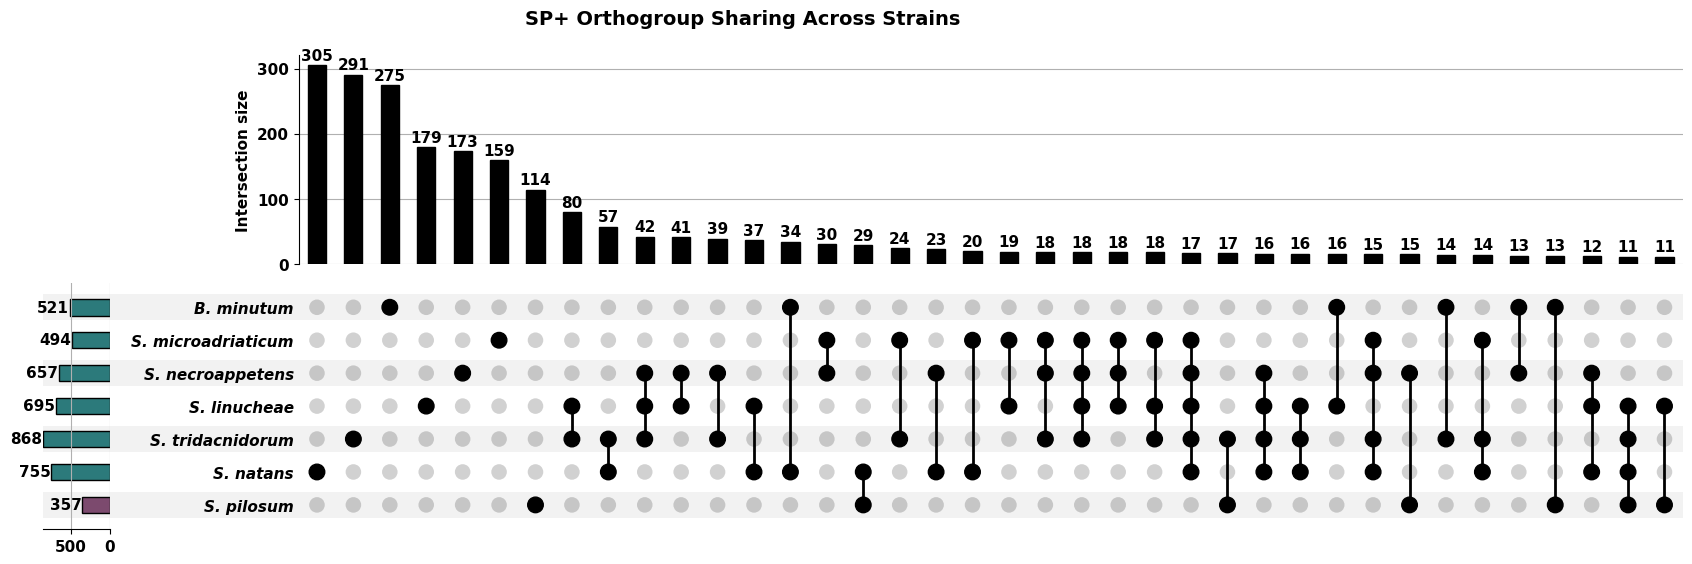

  Core (all 7 strains): 4
  Bmin-private: 275
  Clade-A-only (absent from Bmin): 2010

[SP_NEG] 1016 orthogroups have at least one SP- member (out of 30844 total orthogroups)
  (Plot below only displays intersections with >10 orthogroups; summary counts here are exact totals, unfiltered.)


/usr/local/lib/python3.12/dist-packages/upsetplot/plotting.py:795: FutureWarning: A value is trying to be set on a copy of a DataFrame or Series through chained assignment using an inplace method.
The behavior will change in pandas 3.0. This inplace method will never work because the intermediate object on which we are setting values always behaves as a copy.

For example, when doing 'df[col].method(value, inplace=True)', try using 'df.method({col: value}, inplace=True)' or df[col] = df[col].method(value) instead, to perform the operation inplace on the original object.


  styles["linewidth"].fillna(1, inplace=True)
/usr/local/lib/python3.12/dist-packages/upsetplot/plotting.py:796: FutureWarning: A value is trying to be set on a copy of a DataFrame or Series through chained assignment using an inplace method.
The behavior will change in pandas 3.0. This inplace method will never work because the intermediate object on which we are setting values always behaves as a copy.

For example,

[SAVED] /content/drive/MyDrive/UTokyo/Proteome/Publication/figures_pre/sp_neg_orthogroup_upset.pdf
[SAVED] /content/drive/MyDrive/UTokyo/Proteome/Publication/figures_pre/sp_neg_orthogroup_upset.svg
[SAVED] /content/drive/MyDrive/UTokyo/Proteome/Publication/figures_pre/sp_neg_orthogroup_upset.png


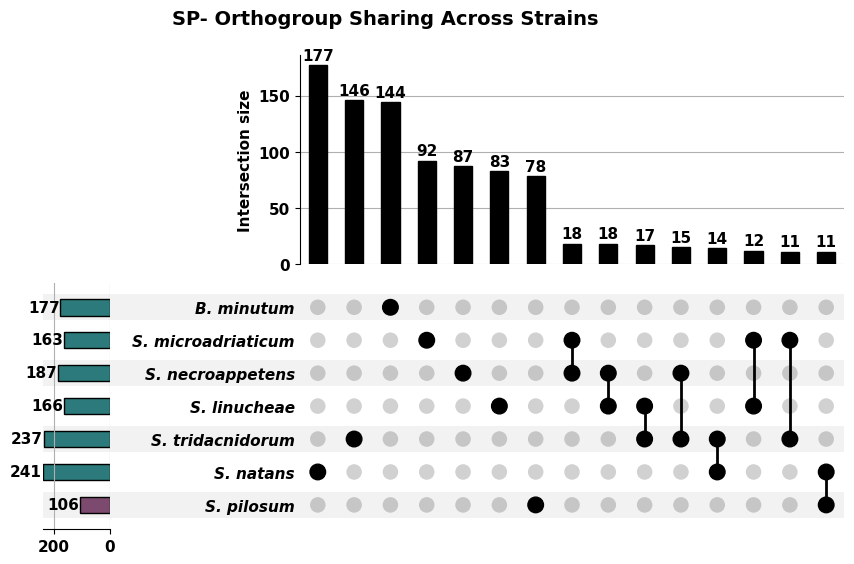

  Core (all 7 strains): 0
  Bmin-private: 144
  Clade-A-only (absent from Bmin): 839

[COMBINED] 3080 orthogroups have at least one secreted member (out of 30844 total orthogroups)
  (Plot below only displays intersections with >10 orthogroups; summary counts here are exact totals, unfiltered.)


/usr/local/lib/python3.12/dist-packages/upsetplot/plotting.py:795: FutureWarning: A value is trying to be set on a copy of a DataFrame or Series through chained assignment using an inplace method.
The behavior will change in pandas 3.0. This inplace method will never work because the intermediate object on which we are setting values always behaves as a copy.

For example, when doing 'df[col].method(value, inplace=True)', try using 'df.method({col: value}, inplace=True)' or df[col] = df[col].method(value) instead, to perform the operation inplace on the original object.


  styles["linewidth"].fillna(1, inplace=True)
/usr/local/lib/python3.12/dist-packages/upsetplot/plotting.py:796: FutureWarning: A value is trying to be set on a copy of a DataFrame or Series through chained assignment using an inplace method.
The behavior will change in pandas 3.0. This inplace method will never work because the intermediate object on which we are setting values always behaves as a copy.

For example,

[SAVED] /content/drive/MyDrive/UTokyo/Proteome/Publication/figures_pre/combined_orthogroup_upset.pdf
[SAVED] /content/drive/MyDrive/UTokyo/Proteome/Publication/figures_pre/combined_orthogroup_upset.svg
[SAVED] /content/drive/MyDrive/UTokyo/Proteome/Publication/figures_pre/combined_orthogroup_upset.png


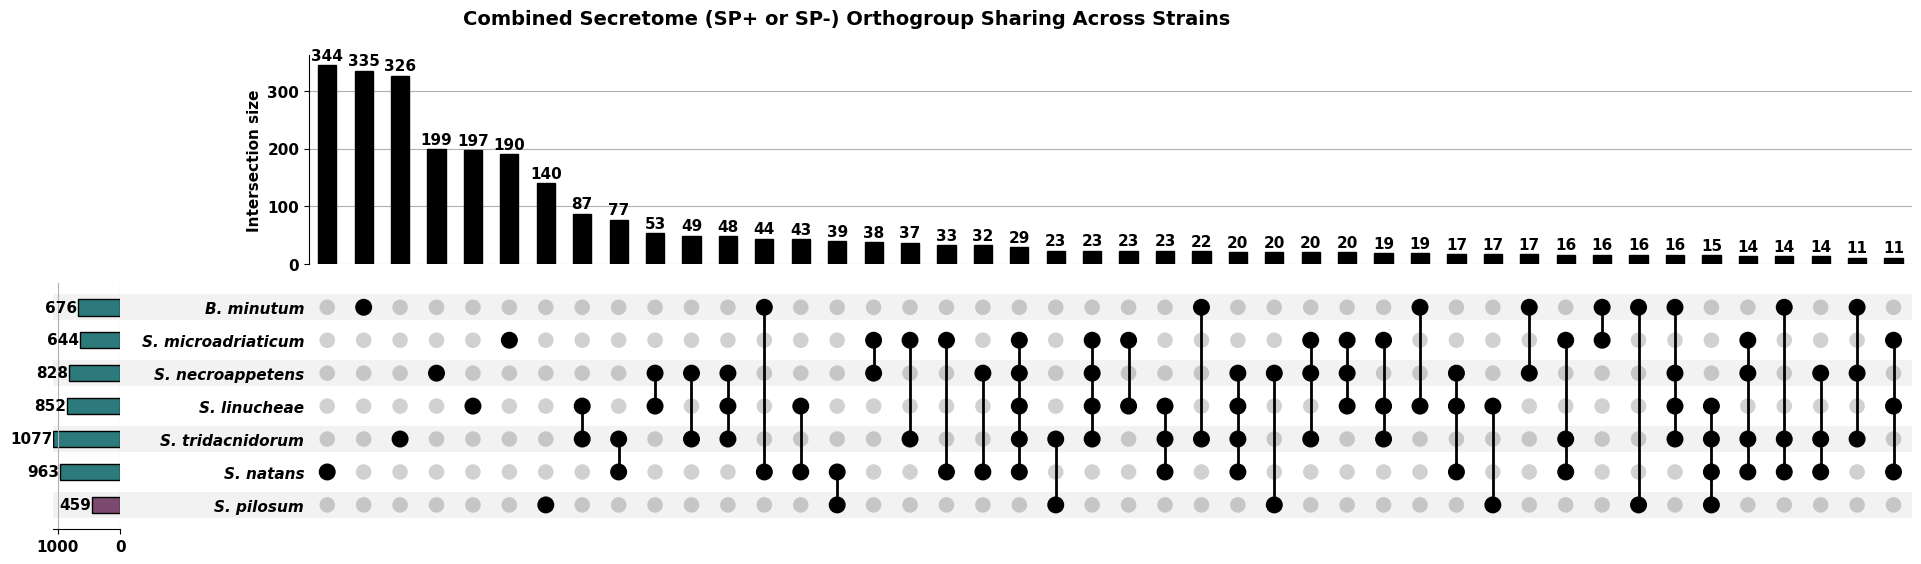

  Core (all 7 strains): 6
  Bmin-private: 335
  Clade-A-only (absent from Bmin): 2404


In [ ]:
# ============================================================
# UpSet plots: SP+, SP-, and combined secretome (SP+ union SP-)
# orthogroup sharing patterns across 7 strains
# Requires: pip install upsetplot  (run once in Colab)
# ============================================================

# !pip install upsetplot -q   # uncomment if not already installed

import os
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib as mpl
from upsetplot import UpSet, from_indicators

# --- Style setup, matching established figure conventions ---
mpl.rcParams['font.weight'] = 'bold'
mpl.rcParams['axes.labelweight'] = 'bold'
mpl.rcParams['pdf.fonttype'] = 42
mpl.rcParams['font.size'] = 11

STRAINS = ["Spil", "Snat", "Stri", "Slin", "Snec", "Smic_jgi", "Bmin"]
SYMBIODINIUM_TEAL = "#2C7A7B"
BREVIOLUM_PURPLE = "#7C4A6E"

# Full species names for axis labels - VERIFY against your own strain records
SPECIES_NAMES = {
    "Spil": "S. pilosum",
    "Snat": "S. natans",
    "Stri": "S. tridacnidorum",
    "Slin": "S. linucheae",
    "Snec": "S. necroappetens",
    "Smic_jgi": "S. microadriaticum",
    "Bmin": "B. minutum",
}
FULL_NAMES = [SPECIES_NAMES[s] for s in STRAINS]

MIN_SUBSET_SIZE = 11  # only display intersections with >10 orthogroups

WIDE_TSV = os.path.join(OUTPUT_DIR, "orthogroup_secretome_tagging_wide.tsv")
FIG_DIR = os.path.join(base, "Publication", "figures_pre")
os.makedirs(FIG_DIR, exist_ok=True)

# ============================================================
# Load tagging table, build SP+/SP-/combined boolean indicators
# ============================================================
wide = pd.read_csv(WIDE_TSV, sep="\t")

for strain in STRAINS:
    wide[f"{strain}_SPpos"] = wide[strain].astype(str).str.contains(r"SP\+", regex=True)
    wide[f"{strain}_SPneg"] = wide[strain].astype(str).str.contains(r"SP\-", regex=True)
    wide[f"{strain}_any"]   = wide[f"{strain}_SPpos"] | wide[f"{strain}_SPneg"]

# ============================================================
# Reusable UpSet plotting function
# ============================================================
def make_upset_plot(suffix, label, title, summary_name):
    """
    suffix: column suffix to use ('SPpos', 'SPneg', or 'any')
    label: short name for filenames (e.g. 'sp_pos', 'sp_neg', 'combined')
    title: plot title
    summary_name: description used in printed summary text
    """
    indicator_cols = [f"{s}_{suffix}" for s in STRAINS]
    subset = wide[wide[indicator_cols].any(axis=1)].copy()

    print(f"\n[{label.upper()}] {subset.shape[0]} orthogroups have at least one "
          f"{summary_name} member (out of {wide.shape[0]} total orthogroups)")
    print(f"  (Plot below only displays intersections with >{MIN_SUBSET_SIZE - 1} orthogroups; "
          f"summary counts here are exact totals, unfiltered.)")

    subset_upset = subset[indicator_cols].rename(
        columns={f"{s}_{suffix}": SPECIES_NAMES[s] for s in STRAINS}
    )
    upset_data = from_indicators(FULL_NAMES, data=subset_upset)

    fig = plt.figure(figsize=(14, 7))
    upset = UpSet(
        upset_data,
        subset_size="count",
        sort_by="cardinality",
        sort_categories_by=None,   # preserve STRAINS order (Spil -> Bmin)
        show_counts=True,
        facecolor="black",
        min_subset_size=MIN_SUBSET_SIZE,
    )
    axes_dict = upset.plot(fig=fig)

    # Recolor totals bars: teal for Symbiodinium, purple for Bmin
    totals_ax = axes_dict["totals"]
    for patch, full_name in zip(totals_ax.patches, reversed(FULL_NAMES)):
        color = BREVIOLUM_PURPLE if full_name == SPECIES_NAMES["Bmin"] else SYMBIODINIUM_TEAL
        patch.set_facecolor(color)

    # Italicize + bold species names
    matrix_ax = axes_dict["matrix"]
    for lbl in matrix_ax.get_yticklabels():
        lbl.set_fontstyle("italic")
        lbl.set_fontweight("bold")

    fig.suptitle(title, fontweight="bold", fontsize=14)
    plt.subplots_adjust(left=0.15, right=0.97, top=0.90, bottom=0.08)

    for ext in ["pdf", "svg", "png"]:
        kwargs = {"dpi": 600} if ext == "png" else {}
        outpath = os.path.join(FIG_DIR, f"{label}_orthogroup_upset.{ext}")
        fig.savefig(outpath, bbox_inches="tight", **kwargs)
        print(f"[SAVED] {outpath}")

    plt.show()

    # Summary counts (exact totals, independent of the plot's min_subset_size filter)
    core_mask = subset_upset.all(axis=1)
    bmin_col = SPECIES_NAMES["Bmin"]
    other_cols = [c for c in FULL_NAMES if c != bmin_col]
    bmin_private_mask = subset_upset[bmin_col] & ~subset_upset[other_cols].any(axis=1)
    clade_a_only_mask = subset_upset[other_cols].any(axis=1) & ~subset_upset[bmin_col]
    print(f"  Core (all 7 strains): {core_mask.sum()}")
    print(f"  Bmin-private: {bmin_private_mask.sum()}")
    print(f"  Clade-A-only (absent from Bmin): {clade_a_only_mask.sum()}")

    return subset_upset

# ============================================================
# Generate all three plots
# ============================================================
sp_pos_data = make_upset_plot("SPpos", "sp_pos", "SP+ Orthogroup Sharing Across Strains", "SP+")
sp_neg_data = make_upset_plot("SPneg", "sp_neg", "SP- Orthogroup Sharing Across Strains", "SP-")
combined_data = make_upset_plot("any", "combined", "Combined Secretome (SP+ or SP-) Orthogroup Sharing Across Strains", "secreted")

In [ ]:
# Check the distribution of "how many strains" for SP- orthogroups,
# to see if 0-core is a hard cliff or if several are at 6/7.

sp_neg_indicator_cols = [f"{s}_SPneg" for s in STRAINS]
sp_neg_subset = wide[wide[sp_neg_indicator_cols].any(axis=1)]

n_strains_with_SPneg = sp_neg_subset[sp_neg_indicator_cols].sum(axis=1)
print(sp_neg_subset.groupby(n_strains_with_SPneg).size().rename("n_orthogroups"))

1    807
2    168
3     30
4     11
Name: n_orthogroups, dtype: int64


# Phylogeny-anchored gain/loss

In [ ]:
# ============================================================
# Re-root the OrthoFinder species tree on Bmin (Breviolum minutum),
# overriding STRIDE's automatic Spil-rooted result, per established
# Symbiodiniaceae outgroup relationships.
# ============================================================

!pip install ete3 -q

import os
from ete3 import Tree

ORTHO_ROOT = os.path.join(base, "9_Ortholog_analysis")
SPECIES_TREE_PATH = os.path.join(ORTHO_ROOT, "Pro_OF_dendroblast", "Species_Tree", "SpeciesTree_rooted.txt")
OUTPUT_TREE_PATH = os.path.join(ORTHO_ROOT, "Pro_OF_dendroblast", "Species_Tree", "SpeciesTree_Bmin_rooted.txt")

with open(SPECIES_TREE_PATH) as f:
    newick_str = f.read().strip()

print("[CHECK] Original tree (Spil-rooted, per STRIDE):")
print(newick_str)

# Try the flexible internal-node-name format first; fall back if OrthoFinder's
# output doesn't include internal labels in this file.
try:
    t = Tree(newick_str, format=1)
except Exception as e:
    print(f"[WARNING] format=1 parse failed ({e}), trying format=0")
    t = Tree(newick_str, format=0)

print("\n[CHECK] Leaf names found in tree:")
leaves = t.get_leaf_names()
print(leaves)

if "Bmin" not in leaves:
    raise ValueError(f"'Bmin' not found as a leaf name. Actual leaves: {leaves} - "
                      f"check exact label used in this tree file before proceeding.")

t.set_outgroup("Bmin")

print("\n[CHECK] Re-rooted tree (Newick, Bmin as outgroup):")
rerooted_newick = t.write(format=1)
print(rerooted_newick)

print("\n[CHECK] ASCII visualization for a quick sanity check:")
print(t.get_ascii(show_internal=False))

with open(OUTPUT_TREE_PATH, "w") as f:
    f.write(rerooted_newick)

print(f"\n[SAVED] {OUTPUT_TREE_PATH}")

     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 4.8/4.8 MB 44.8 MB/s eta 0:00:00
  Preparing metadata (setup.py) ... done
[CHECK] Original tree (Spil-rooted, per STRIDE):
(Spil:0.125036,(Bmin:0.483142,(Snat:0.182549,(Stri:0.0737008,(Slin:0.0729991,(Snec:0.0444681,Smic_jgi:0.161522)0.373286:0.126565)0.2299:0.0939299)0.390886:0.132691)0.303446:0.143921)1:0.125036);

[CHECK] Leaf names found in tree:
['Spil', 'Bmin', 'Snat', 'Stri', 'Slin', 'Snec', 'Smic_jgi']

[CHECK] Re-rooted tree (Newick, Bmin as outgroup):
(Bmin:0.241571,((Snat:0.182549,(Stri:0.0737008,(Slin:0.0729991,(Snec:0.0444681,Smic_jgi:0.161522)0.373286:0.126565)0.2299:0.0939299)0.390886:0.132691)0.303446:0.143921,Spil:0.250072)1:0.241571);

[CHECK] ASCII visualization for a quick sanity check:

   /-Bmin
  |
  |      /-Snat
--|   /-|
  |  |  |   /-Stri
  |  |   \-|
  |  |     |   /-Slin
   \-|      \-|
     |        |   /-Snec
     |         \-|
     |            \-Smic_jgi
     |
      \-Spil

[SAVED] /content/drive/MyDrive/UT

# Stacked bar chart of conservation

[SAVED] /content/drive/MyDrive/UTokyo/Proteome/Publication/figures_pre/secretome_conservation_stacked_bar.pdf
[SAVED] /content/drive/MyDrive/UTokyo/Proteome/Publication/figures_pre/secretome_conservation_stacked_bar.svg
[SAVED] /content/drive/MyDrive/UTokyo/Proteome/Publication/figures_pre/secretome_conservation_stacked_bar.png


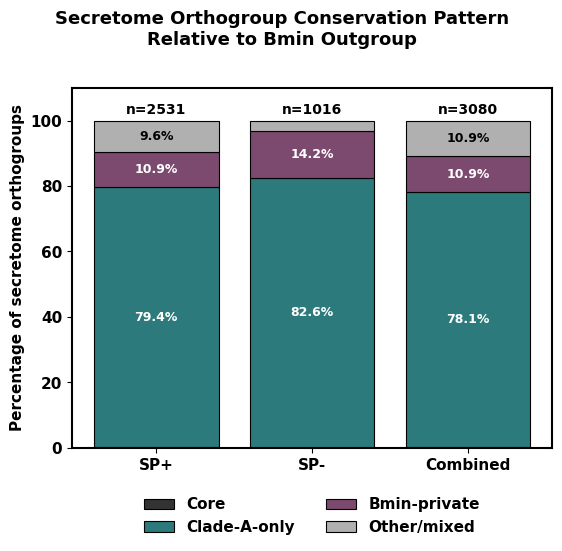


           Core  Clade-A-only  Bmin-private  Other/mixed  Total
SP+          4          2010           275          242   2531
SP-          0           839           144           33   1016
Combined     6          2404           335          335   3080


In [ ]:
# ============================================================
# Main-figure alternative: 100% stacked bar chart of conservation
# categories (Core / Clade-A-only / Bmin-private / Other-mixed)
# across SP+, SP-, and Combined secretome categories.
# ============================================================

import os
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib as mpl

mpl.rcParams['font.weight'] = 'bold'
mpl.rcParams['axes.labelweight'] = 'bold'
mpl.rcParams['pdf.fonttype'] = 42
mpl.rcParams['font.size'] = 11

STRAINS = ["Spil", "Snat", "Stri", "Slin", "Snec", "Smic_jgi", "Bmin"]
SYMBIODINIUM_TEAL = "#2C7A7B"
BREVIOLUM_PURPLE = "#7C4A6E"
CORE_COLOR = "#333333"
OTHER_COLOR = "#B0B0B0"

WIDE_TSV = os.path.join(OUTPUT_DIR, "orthogroup_secretome_tagging_wide.tsv")
FIG_DIR = os.path.join(base, "Publication", "figures_pre")
os.makedirs(FIG_DIR, exist_ok=True)

wide = pd.read_csv(WIDE_TSV, sep="\t")
for strain in STRAINS:
    wide[f"{strain}_SPpos"] = wide[strain].astype(str).str.contains(r"SP\+", regex=True)
    wide[f"{strain}_SPneg"] = wide[strain].astype(str).str.contains(r"SP\-", regex=True)
    wide[f"{strain}_any"]   = wide[f"{strain}_SPpos"] | wide[f"{strain}_SPneg"]

def categorize(suffix):
    cols = [f"{s}_{suffix}" for s in STRAINS]
    subset = wide[wide[cols].any(axis=1)]
    m = subset[cols]
    core = m.all(axis=1).sum()
    other_cols = [f"{s}_{suffix}" for s in STRAINS if s != "Bmin"]
    bmin_private = (m[f"Bmin_{suffix}"] & ~m[other_cols].any(axis=1)).sum()
    clade_a_only = (m[other_cols].any(axis=1) & ~m[f"Bmin_{suffix}"]).sum()
    total = subset.shape[0]
    other = total - core - bmin_private - clade_a_only
    return {"Core": core, "Clade-A-only": clade_a_only, "Bmin-private": bmin_private,
            "Other/mixed": other, "Total": total}

categories = {"SP+": categorize("SPpos"), "SP-": categorize("SPneg"), "Combined": categorize("any")}
df = pd.DataFrame(categories).T
totals = df.pop("Total")

# Convert to percentages for the 100% stacked bar
pct = df.div(df.sum(axis=1), axis=0) * 100

# ============================================================
# Plot
# ============================================================
fig, ax = plt.subplots(figsize=(6, 6))

segment_order = ["Core", "Clade-A-only", "Bmin-private", "Other/mixed"]
colors = {"Core": CORE_COLOR, "Clade-A-only": SYMBIODINIUM_TEAL,
          "Bmin-private": BREVIOLUM_PURPLE, "Other/mixed": OTHER_COLOR}

bottom = pd.Series([0.0] * len(pct), index=pct.index)
bars = {}
for seg in segment_order:
    bars[seg] = ax.bar(pct.index, pct[seg], bottom=bottom, label=seg,
                        color=colors[seg], edgecolor="black", linewidth=0.8)
    bottom += pct[seg]

# Annotate total n above each bar
for i, cat in enumerate(pct.index):
    ax.text(i, 102, f"n={totals[cat]}", ha="center", fontweight="bold", fontsize=10)

# Annotate percentage inside each segment (only if segment is large enough to read)
for seg in segment_order:
    running = pd.Series([0.0] * len(pct), index=pct.index)
    for s in segment_order:
        if s == seg:
            break
        running += pct[s]
    for i, cat in enumerate(pct.index):
        val = pct.loc[cat, seg]
        if val > 4:  # skip labeling tiny slivers
            ax.text(i, running[cat] + val / 2, f"{val:.1f}%", ha="center", va="center",
                     fontweight="bold", fontsize=9,
                     color="white" if seg in ("Core", "Clade-A-only", "Bmin-private") else "black")

ax.set_ylabel("Percentage of secretome orthogroups", fontweight="bold")
ax.set_ylim(0, 110)
ax.set_yticks(range(0, 101, 20))
ax.legend(loc="lower center", bbox_to_anchor=(0.5, -0.28), ncol=2, frameon=False)

# Full frame, matching established style
for spine in ax.spines.values():
    spine.set_linewidth(1.5)
    spine.set_visible(True)

fig.suptitle("Secretome Orthogroup Conservation Pattern\nRelative to Bmin Outgroup",
             fontweight="bold", fontsize=13)
plt.subplots_adjust(left=0.15, right=0.95, top=0.85, bottom=0.25)

for ext in ["pdf", "svg", "png"]:
    kwargs = {"dpi": 600} if ext == "png" else {}
    outpath = os.path.join(FIG_DIR, f"secretome_conservation_stacked_bar.{ext}")
    fig.savefig(outpath, bbox_inches="tight", **kwargs)
    print(f"[SAVED] {outpath}")

plt.show()
print("\n", df.assign(Total=totals))

## Orthogroup membership type

[LEFT PANEL COUNTS]
Secretome only          135
Non-secretome only    27764
Mixed                  2945
dtype: int64
Total = 30,844
[SAVED] /content/drive/MyDrive/UTokyo/Proteome/Publication/figures_pre/orthogroup_membership_panelA.pdf
[SAVED] /content/drive/MyDrive/UTokyo/Proteome/Publication/figures_pre/orthogroup_membership_panelA.svg
[SAVED] /content/drive/MyDrive/UTokyo/Proteome/Publication/figures_pre/orthogroup_membership_panelA.png


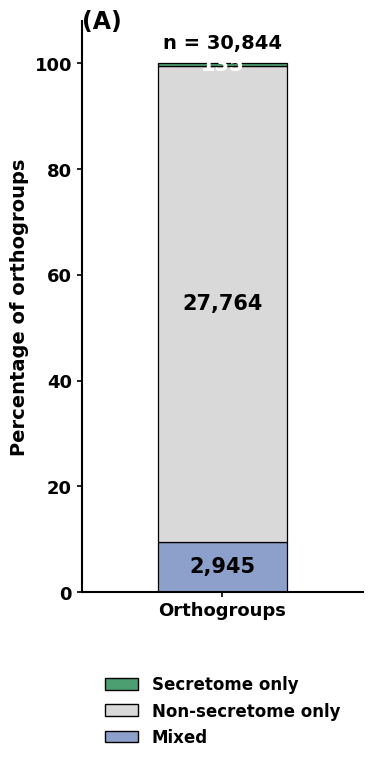

In [ ]:
# ============================================================
# Panel A (standalone): Orthogroup membership type
# One 100% stacked bar - Secretome only / Non-secretome only /
# Mixed.
# ============================================================

import os
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib as mpl
from matplotlib.patches import Patch

mpl.rcParams["font.weight"] = "bold"
mpl.rcParams["axes.labelweight"] = "bold"
mpl.rcParams["pdf.fonttype"] = 42
mpl.rcParams["ps.fonttype"] = 42
mpl.rcParams["font.size"] = 14

STRAINS = ["Spil", "Snat", "Stri", "Slin", "Snec", "Smic_jgi", "Bmin"]

WIDE_TSV = os.path.join(OUTPUT_DIR, "orthogroup_secretome_tagging_wide.tsv")
FIG_DIR = os.path.join(base, "Publication", "figures_pre")
os.makedirs(FIG_DIR, exist_ok=True)

wide = pd.read_csv(WIDE_TSV, sep="\t")

# ------------------------------------------------------------
# Status parsing
# ------------------------------------------------------------
for strain in STRAINS:
    values = wide[strain].fillna("absent").astype(str).str.strip()
    wide[f"{strain}_SPpos"] = values.str.contains(r"(?:^|;)SP\+(?:;|$)", regex=True, na=False)
    wide[f"{strain}_SPneg"] = values.str.contains(r"(?:^|;)SP\-(?:;|$)", regex=True, na=False)
    wide[f"{strain}_secretome"] = wide[f"{strain}_SPpos"] | wide[f"{strain}_SPneg"]
    wide[f"{strain}_nonsecretome"] = values.str.contains(r"(?:^|;)not_secreted(?:;|$)", regex=True, na=False)

secretome_any = wide[[f"{s}_secretome" for s in STRAINS]].any(axis=1)
nonsecretome_any = wide[[f"{s}_nonsecretome" for s in STRAINS]].any(axis=1)

membership_counts = pd.Series({
    "Secretome only": int((secretome_any & ~nonsecretome_any).sum()),
    "Non-secretome only": int((nonsecretome_any & ~secretome_any).sum()),
    "Mixed": int((secretome_any & nonsecretome_any).sum()),
})

membership_total = membership_counts.sum()
membership_pct = membership_counts / membership_total * 100

print("[LEFT PANEL COUNTS]")
print(membership_counts)
print(f"Total = {membership_total:,}")

# ------------------------------------------------------------
# Plot settings
# ------------------------------------------------------------
left_colors = {
    "Secretome only": "#4C9F70",
    "Non-secretome only": "#D9D9D9",
    "Mixed": "#8DA0CB",
}

def _is_dark(hex_color):
    hex_color = hex_color.lstrip("#")
    r, g, b = int(hex_color[0:2], 16), int(hex_color[2:4], 16), int(hex_color[4:6], 16)
    return (0.299 * r + 0.587 * g + 0.114 * b) < 140

# ------------------------------------------------------------
# DIRECT width control - no cross-panel matching needed, this
# figure has only one bar/category, so this value IS the visual width.
# ------------------------------------------------------------
BAR_WIDTH = 0.6  # adjust freely - 0 to ~0.9 is the sane range for a single category
BAR_X = 0

# ------------------------------------------------------------
# Plot
# ------------------------------------------------------------
plt.close("all")
fig, ax = plt.subplots(figsize=(4.2, 8.4))

left_order = ["Secretome only", "Non-secretome only", "Mixed"]
stack_order = list(reversed(left_order))  # bottom-to-top draw order for top-to-bottom reading

bottom = 0.0
for seg in stack_order:
    val = membership_pct[seg]
    ax.bar(BAR_X, val, bottom=bottom, color=left_colors[seg],
    edgecolor="black", linewidth=0.9, width=BAR_WIDTH, label=seg,)
    mid_y = bottom + val / 2
    ax.text(BAR_X, mid_y, f"{membership_counts[seg]:,}", ha="center", va="center",
            fontsize=15, fontweight="bold",
            color="white" if _is_dark(left_colors[seg]) else "black")
    bottom += val

ax.text(BAR_X, 102.0, f"n = {membership_total:,}", ha="center", va="bottom",
        fontsize=14, fontweight="bold")

ax.set_ylabel("Percentage of orthogroups", fontweight="bold", fontsize=14)
ax.set_ylim(0, 108)
ax.set_yticks(range(0, 101, 20))
ax.set_xlim(-0.65, 0.65)
ax.set_xticks([BAR_X])
ax.set_xticklabels(["Orthogroups"])
ax.tick_params(axis="x", labelsize=13, width=1.2)
ax.tick_params(axis="y", labelsize=13, width=1.2)
ax.spines["top"].set_visible(False)
ax.spines["right"].set_visible(False)
ax.spines["left"].set_linewidth(1.5)
ax.spines["bottom"].set_linewidth(1.5)
ax.text(0, 1.02, "(A)", transform=ax.transAxes, fontsize=17, fontweight="bold", ha="left", va="top")

legend_handles = [Patch(facecolor=left_colors[seg], edgecolor="black", label=seg) for seg in left_order]
ax.legend(handles=legend_handles, loc="upper center", bbox_to_anchor=(0.5, -0.12),
          frameon=False, fontsize=12, ncol=1)

plt.subplots_adjust(left=0.28, right=0.95, top=0.90, bottom=0.22)

for ext in ["pdf", "svg", "png"]:
    kwargs = {"dpi": 600} if ext == "png" else {}
    outpath = os.path.join(FIG_DIR, f"orthogroup_membership_panelA.{ext}")
    fig.savefig(outpath, bbox_inches="tight", **kwargs)
    print(f"[SAVED] {outpath}")

plt.show()

## Conservation pattern

[CHECK] Orthogroups in whole-proteome bar: 30,844
[WARNING] Expected 31,080 orthogroups, got 30,844
[SAVED] /content/drive/MyDrive/UTokyo/Proteome/Publication/figures_pre/orthogroup_conservation_panelB.pdf
[SAVED] /content/drive/MyDrive/UTokyo/Proteome/Publication/figures_pre/orthogroup_conservation_panelB.svg
[SAVED] /content/drive/MyDrive/UTokyo/Proteome/Publication/figures_pre/orthogroup_conservation_panelB.png


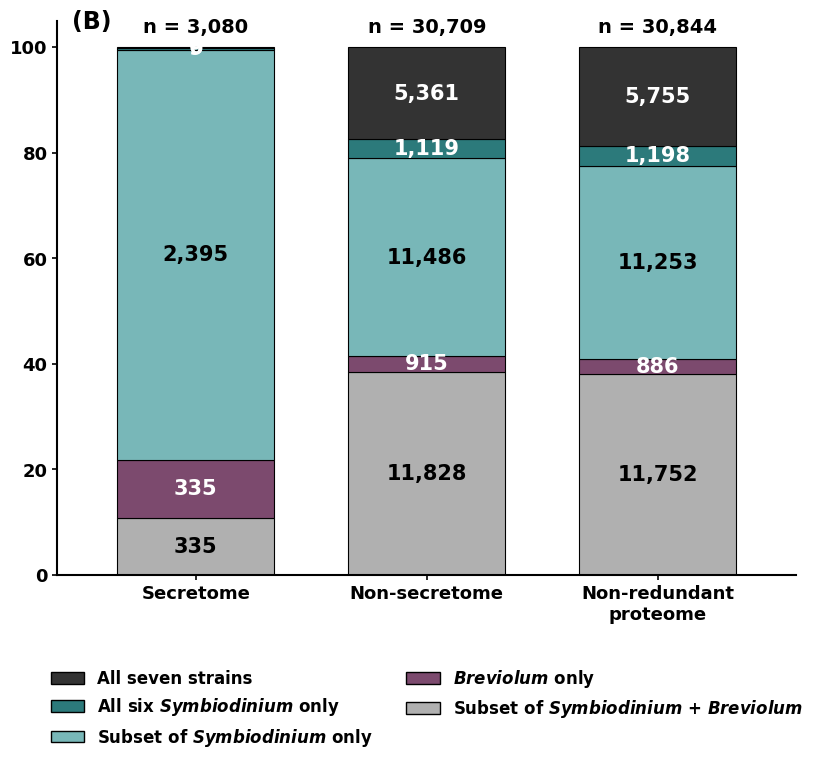


[RIGHT PANEL COUNTS]
                         All seven strains  All six $\it{Symbiodinium}$ only  \
Secretome                                6                                 9   
Non-secretome                         5361                              1119   
Non-redundant\nproteome               5755                              1198   

                         Subset of $\it{Symbiodinium}$ only  \
Secretome                                              2395   
Non-secretome                                         11486   
Non-redundant\nproteome                               11253   

                         $\it{Breviolum}$ only  \
Secretome                                  335   
Non-secretome                              915   
Non-redundant\nproteome                    886   

                         Subset of $\it{Symbiodinium}$ + $\it{Breviolum}$  \
Secretome                                                             335   
Non-secretome                                    

In [ ]:
# ============================================================
# Panel B (standalone): Conservation pattern
# Three 100% stacked bars - Secretome / Non-secretome /
# Non-redundant proteome, each broken into 5 conservation categories.
# ============================================================

import os
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib as mpl
from matplotlib.patches import Patch

mpl.rcParams["font.weight"] = "bold"
mpl.rcParams["axes.labelweight"] = "bold"
mpl.rcParams["pdf.fonttype"] = 42
mpl.rcParams["ps.fonttype"] = 42
mpl.rcParams["font.size"] = 14

STRAINS = ["Spil", "Snat", "Stri", "Slin", "Snec", "Smic_jgi", "Bmin"]
SYMBIODINIUM = [s for s in STRAINS if s != "Bmin"]

WIDE_TSV = os.path.join(OUTPUT_DIR, "orthogroup_secretome_tagging_wide.tsv")
FIG_DIR = os.path.join(base, "Publication", "figures_pre")
os.makedirs(FIG_DIR, exist_ok=True)

wide = pd.read_csv(WIDE_TSV, sep="\t")

for strain in STRAINS:
    values = wide[strain].fillna("absent").astype(str).str.strip()
    wide[f"{strain}_SPpos"] = values.str.contains(r"(?:^|;)SP\+(?:;|$)", regex=True, na=False)
    wide[f"{strain}_SPneg"] = values.str.contains(r"(?:^|;)SP\-(?:;|$)", regex=True, na=False)
    wide[f"{strain}_secretome"] = wide[f"{strain}_SPpos"] | wide[f"{strain}_SPneg"]
    wide[f"{strain}_nonsecretome"] = values.str.contains(r"(?:^|;)not_secreted(?:;|$)", regex=True, na=False)
    wide[f"{strain}_whole"] = values.ne("absent")

def categorize(suffix):
    cols = [f"{s}_{suffix}" for s in STRAINS]
    sym_cols = [f"{s}_{suffix}" for s in SYMBIODINIUM]
    bmin_col = f"Bmin_{suffix}"
    matrix = wide.loc[wide[cols].any(axis=1), cols].copy()
    sym_any = matrix[sym_cols].any(axis=1)
    sym_all = matrix[sym_cols].all(axis=1)
    bmin_present = matrix[bmin_col]
    result = {
        "All seven strains": int((sym_all & bmin_present).sum()),
        r"All six $\it{Symbiodinium}$ only": int((sym_all & ~bmin_present).sum()),
        r"Subset of $\it{Symbiodinium}$ only": int((sym_any & ~sym_all & ~bmin_present).sum()),
        r"$\it{Breviolum}$ only": int((bmin_present & ~sym_any).sum()),
        r"Subset of $\it{Symbiodinium}$ + $\it{Breviolum}$": int((bmin_present & sym_any & ~sym_all).sum()),
    }
    if sum(result.values()) != matrix.shape[0]:
        raise RuntimeError(f"Category counts for {suffix} do not sum correctly")
    return result

comparisons = {
    "Secretome": categorize("secretome"),
    "Non-secretome": categorize("nonsecretome"),
    "Non-redundant\nproteome": categorize("whole"),
}

segment_order = [
    "All seven strains",
    r"All six $\it{Symbiodinium}$ only",
    r"Subset of $\it{Symbiodinium}$ only",
    r"$\it{Breviolum}$ only",
    r"Subset of $\it{Symbiodinium}$ + $\it{Breviolum}$",
]
stack_order = list(reversed(segment_order))

counts = pd.DataFrame(comparisons).T
counts = counts[segment_order]
totals = counts.sum(axis=1)
pct = counts.div(totals, axis=0) * 100

whole_total = totals.loc["Non-redundant\nproteome"]
print(f"[CHECK] Orthogroups in whole-proteome bar: {whole_total:,}")
if whole_total != 31080:
    print(f"[WARNING] Expected 31,080 orthogroups, got {whole_total:,}")

right_colors = {
    "All seven strains": "#333333",
    r"All six $\it{Symbiodinium}$ only": "#2C7A7B",
    r"Subset of $\it{Symbiodinium}$ only": "#78B7B8",
    r"$\it{Breviolum}$ only": "#7C4A6E",
    r"Subset of $\it{Symbiodinium}$ + $\it{Breviolum}$": "#B0B0B0",
}

def _is_dark(hex_color):
    hex_color = hex_color.lstrip("#")
    r, g, b = int(hex_color[0:2], 16), int(hex_color[2:4], 16), int(hex_color[4:6], 16)
    return (0.299 * r + 0.587 * g + 0.114 * b) < 140

# ------------------------------------------------------------
# DIRECT width control - 3 categories in this figure only, no
# other panel to match against.
# ------------------------------------------------------------
BAR_WIDTH = 0.68  # adjust freely

# ------------------------------------------------------------
# Plot
# ------------------------------------------------------------
plt.close("all")
fig, ax = plt.subplots(figsize=(8.4, 8.4))

bottom = pd.Series(0.0, index=pct.index, dtype=float)
bottoms_by_segment = {}
for seg in stack_order:
    bottoms_by_segment[seg] = bottom.copy()
    ax.bar(pct.index, pct[seg], bottom=bottom, color=right_colors[seg],
           edgecolor="black", linewidth=0.8, width=BAR_WIDTH, label=seg)
    bottom += pct[seg]

for comparison in pct.index:
    for seg in segment_order:
        val = pct.loc[comparison, seg]
        if val <= 0:
            continue
        mid_y = bottoms_by_segment[seg][comparison] + val / 2
        ax.text(comparison, mid_y, f"{counts.loc[comparison, seg]:,}", ha="center", va="center",
                fontsize=15, fontweight="bold",
                color="white" if _is_dark(right_colors[seg]) else "black")

for comparison in pct.index:
    ax.text(comparison, 102.0, f"n = {totals.loc[comparison]:,}", ha="center", va="bottom",
            fontsize=14, fontweight="bold")

ax.tick_params(axis="x", labelsize=13, width=1.2)
ax.tick_params(axis="y", labelsize=13, width=1.2)
ax.spines["top"].set_visible(False)
ax.spines["right"].set_visible(False)
ax.spines["left"].set_linewidth(1.5)
ax.spines["bottom"].set_linewidth(1.5)
ax.text(0.02, 1.02, "(B)", transform=ax.transAxes, fontsize=17, fontweight="bold", ha="left", va="top")
ax.set_xlim(-0.6, len(pct.index) - 1 + 0.6)

legend_handles = [Patch(facecolor=right_colors[k], edgecolor="black", label=k) for k in segment_order]
ax.legend(handles=legend_handles, loc="upper center", bbox_to_anchor=(0.5, -0.14),
          frameon=False, fontsize=12, ncol=2)

plt.subplots_adjust(left=0.10, right=0.98, top=0.90, bottom=0.24)

for ext in ["pdf", "svg", "png"]:
    kwargs = {"dpi": 600} if ext == "png" else {}
    outpath = os.path.join(FIG_DIR, f"orthogroup_conservation_panelB.{ext}")
    fig.savefig(outpath, bbox_inches="tight", **kwargs)
    print(f"[SAVED] {outpath}")

plt.show()

print("\n[RIGHT PANEL COUNTS]")
print(counts.assign(Total=totals))
print("\n[RIGHT PANEL PERCENTAGES]")
print(pct.round(2))

In [ ]:
print(counts.assign(Total=totals))

                         All seven strains  All six $\it{Symbiodinium}$ only  \
Secretome                                6                                 9   
Non-secretome                         5361                              1119   
Non-redundant\nproteome               5755                              1198   

                         Subset of $\it{Symbiodinium}$ only  \
Secretome                                              2395   
Non-secretome                                         11486   
Non-redundant\nproteome                               11253   

                         $\it{Breviolum}$ only  \
Secretome                                  335   
Non-secretome                              915   
Non-redundant\nproteome                    886   

                         $\it{Symbiodinium}$ and $\it{Breviolum}$  Total  
Secretome                                                     335   3080  
Non-secretome                                               11828  30709  


## Phylogeny-anchored lineage-restricted secretome

[CHECK] Ladderized leaf order (top to bottom): ['Bmin', 'Spil', 'Snat', 'Stri', 'Slin', 'Snec', 'Smic_jgi']

[CHECK] Lineage-restriction percentage per tip (numerator / denominator = pct%):
  Bmin | Secretome only: 13 / 29 = 44.8%
  Bmin | Non-secretome only: 842 / 16387 = 5.1%
  Bmin | Mixed: 31 / 1977 = 1.6%
  Spil | Secretome only: 35 / 39 = 89.7%
  Spil | Non-secretome only: 5678 / 16382 = 34.7%
  Spil | Mixed: 615 / 2137 = 28.8%
  Snat | Secretome only: 40 / 50 = 80.0%
  Snat | Non-secretome only: 5094 / 16125 = 31.6%
  Snat | Mixed: 620 / 2246 = 27.6%
  Stri | Secretome only: 57 / 66 = 86.4%
  Stri | Non-secretome only: 6380 / 17862 = 35.7%
  Stri | Mixed: 717 / 2385 = 30.1%
  Slin | Secretome only: 41 / 50 = 82.0%
  Slin | Non-secretome only: 5630 / 16449 = 34.2%
  Slin | Mixed: 667 / 2302 = 29.0%
  Snec | Secretome only: 55 / 64 = 85.9%
  Snec | Non-secretome only: 6702 / 17760 = 37.7%
  Snec | Mixed: 692 / 2345 = 29.5%
  Smic_jgi | Secretome only: 25 / 29 = 86.2%
  Smic_jgi | 

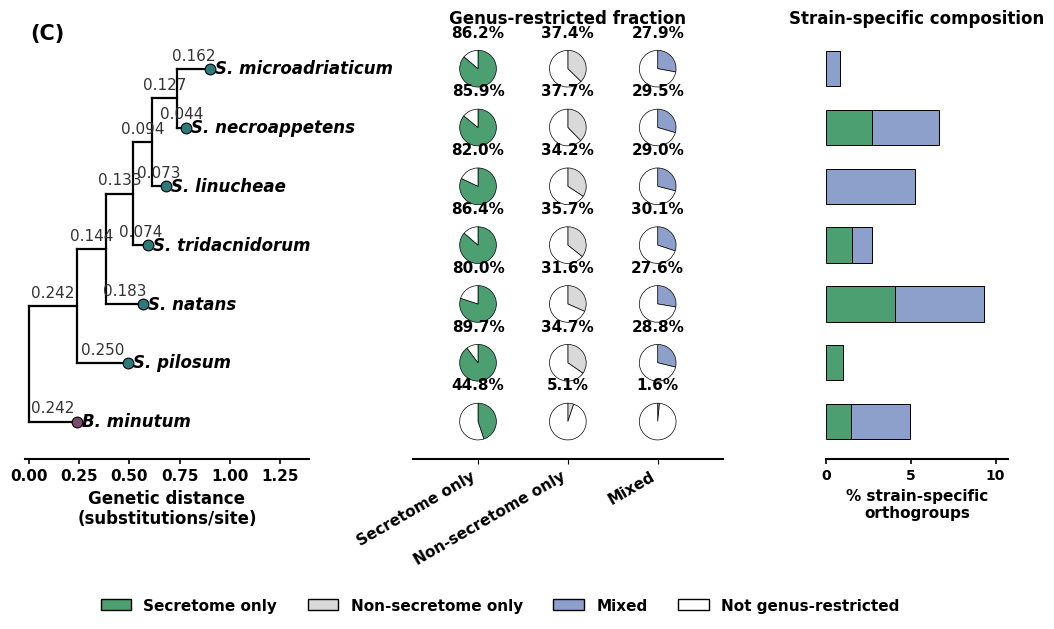


[TABLE] Lineage restriction detail (genus-restricted % and species-private counts):
  strain           category  genus_restricted  category_total  pct_genus_restricted  species_private
    Bmin     Secretome only                13              29                  44.8               13
    Bmin Non-secretome only               842           16387                   5.1              842
    Bmin              Mixed                31            1977                   1.6               31
    Spil     Secretome only                35              39                  89.7                1
    Spil Non-secretome only              5678           16382                  34.7              102
    Spil              Mixed               615            2137                  28.8                0
    Snat     Secretome only                40              50                  80.0               10
    Snat Non-secretome only              5094           16125                  31.6              224
    Sn

In [ ]:
# ============================================================
# Panel C (standalone): Phylogeny-anchored lineage-restriction
# breakdown - tree (Bmin-rooted) + dot matrix showing, for each
# strain and secretion category, the PERCENTAGE of that strain's
# orthogroups (within that category) that are entirely absent
# from the reciprocal genus.
#
# Switched from raw counts to percentages: raw counts alone can't
# distinguish "genuinely restricted" from "this strain just has a
# bigger secretome/genome overall" - percentage, normalized to each
# strain's own total participation in that category, directly
# supports a defensible restriction claim.
#
# NOTE: This is a TIP-LEVEL PRESENCE-PATTERN proxy, not formal
# ancestral gain/loss reconciliation on internal branches.
# ============================================================

import os
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib as mpl
from ete3 import Tree
from matplotlib.patches import Patch

mpl.rcParams["font.weight"] = "bold"
mpl.rcParams["axes.labelweight"] = "bold"
mpl.rcParams["pdf.fonttype"] = 42
mpl.rcParams["ps.fonttype"] = 42
mpl.rcParams["font.size"] = 14

STRAINS = ["Spil", "Snat", "Stri", "Slin", "Snec", "Smic_jgi", "Bmin"]
SPECIES_NAMES = {
    "Spil": "S. pilosum", "Snat": "S. natans", "Stri": "S. tridacnidorum",
    "Slin": "S. linucheae", "Snec": "S. necroappetens",
    "Smic_jgi": "S. microadriaticum", "Bmin": "B. minutum",
}
SYMBIODINIUM_TEAL = "#2C7A7B"
BREVIOLUM_PURPLE = "#7C4A6E"

CATEGORY_COLORS = {
    "Secretome only": "#4C9F70",
    "Non-secretome only": "#D9D9D9",
    "Mixed": "#8DA0CB",
}
CATEGORIES = ["Secretome only", "Non-secretome only", "Mixed"]

ORTHO_ROOT = os.path.join(base, "9_Ortholog_analysis")
TREE_PATH = os.path.join(ORTHO_ROOT, "Pro_OF_dendroblast", "Species_Tree", "SpeciesTree_Bmin_rooted.txt")
WIDE_TSV = os.path.join(OUTPUT_DIR, "orthogroup_secretome_tagging_wide.tsv")
FIG_DIR = os.path.join(base, "Publication", "figures_pre")
os.makedirs(FIG_DIR, exist_ok=True)

with open(TREE_PATH) as f:
    t = Tree(f.read().strip(), format=1)
t.ladderize()
leaf_order = t.get_leaf_names()
print(f"[CHECK] Ladderized leaf order (top to bottom): {leaf_order}")

y_positions = {name: i for i, name in enumerate(leaf_order)}

def assign_coords(node, parent_x=0.0):
    node.add_feature("x", parent_x + (node.dist if not node.is_root() else 0.0))
    if node.is_leaf():
        node.add_feature("y", y_positions[node.name])
    else:
        for child in node.children:
            assign_coords(child, node.x)
        node.add_feature("y", sum(c.y for c in node.children) / len(node.children))
    return node.y

assign_coords(t)

wide = pd.read_csv(WIDE_TSV, sep="\t")
for strain in STRAINS:
    values = wide[strain].fillna("absent").astype(str).str.strip()
    wide[f"{strain}_SPpos"] = values.str.contains(r"(?:^|;)SP\+(?:;|$)", regex=True, na=False)
    wide[f"{strain}_SPneg"] = values.str.contains(r"(?:^|;)SP\-(?:;|$)", regex=True, na=False)
    wide[f"{strain}_any"] = wide[f"{strain}_SPpos"] | wide[f"{strain}_SPneg"]
    wide[f"{strain}_nonsecretome"] = values.str.contains(r"(?:^|;)not_secreted(?:;|$)", regex=True, na=False)
    wide[f"{strain}_whole"] = values.ne("absent")

secretome_any = wide[[f"{s}_any" for s in STRAINS]].any(axis=1)
nonsecretome_any = wide[[f"{s}_nonsecretome" for s in STRAINS]].any(axis=1)

wide["category"] = "Mixed"
wide.loc[secretome_any & ~nonsecretome_any, "category"] = "Secretome only"
wide.loc[nonsecretome_any & ~secretome_any, "category"] = "Non-secretome only"

clade_a_strains = [s for s in STRAINS if s != "Bmin"]

def lineage_restriction_pct(strain):
    if strain == "Bmin":
        participates = wide["Bmin_whole"]
        restricted = wide["Bmin_whole"] & ~wide[[f"{s}_whole" for s in clade_a_strains]].any(axis=1)
    else:
        participates = wide[f"{strain}_whole"]
        restricted = wide[f"{strain}_whole"] & ~wide["Bmin_whole"]

    result = {}
    for cat in CATEGORIES:
        cat_mask = wide["category"] == cat
        denom = int((participates & cat_mask).sum())
        numer = int((restricted & cat_mask).sum())
        pct = (numer / denom * 100) if denom > 0 else 0.0
        result[cat] = {"numerator": numer, "denominator": denom, "pct": pct}
    return result

tip_pct = {s: lineage_restriction_pct(s) for s in STRAINS}

print("\n[CHECK] Lineage-restriction percentage per tip (numerator / denominator = pct%):")
for s in leaf_order:
    for cat in CATEGORIES:
        d = tip_pct[s][cat]
        print(f"  {s} | {cat}: {d['numerator']} / {d['denominator']} = {d['pct']:.1f}%")

def species_private_breakdown(strain):
    others = [s for s in STRAINS if s != strain]
    private_mask = wide[f"{strain}_whole"] & ~wide[[f"{s}_whole" for s in others]].any(axis=1)
    result = {cat: int((private_mask & (wide["category"] == cat)).sum()) for cat in CATEGORIES}
    result["total"] = int(private_mask.sum())
    return result

tip_private = {s: species_private_breakdown(s) for s in STRAINS}

print("\n[CHECK] Species-private orthogroup breakdown per tip:")
for s in leaf_order:
    print(f"  {s}: {tip_private[s]}")

plt.close("all")

TREE_WIDTH_RATIO = 1.1
DOTS_WIDTH_RATIO = 1.2
PRIVATE_BAR_WIDTH_RATIO = 0.7

fig, (ax_tree, ax_dots, ax_private) = plt.subplots(
    1, 3, figsize=(10.8, 7.0),
    gridspec_kw={"width_ratios": [TREE_WIDTH_RATIO, DOTS_WIDTH_RATIO, PRIVATE_BAR_WIDTH_RATIO]},
    sharey=True
)

BRANCH_LINEWIDTH = 1.6

def draw_branches(node, ax):
    for child in node.children:
        ax.plot([node.x, child.x], [child.y, child.y], color="black", linewidth=BRANCH_LINEWIDTH)
        draw_branches(child, ax)
    if len(node.children) > 1:
        ys = [c.y for c in node.children]
        ax.plot([node.x, node.x], [min(ys), max(ys)], color="black", linewidth=BRANCH_LINEWIDTH)

def draw_branch_length_labels(node, ax):
    for child in node.children:
        mid_x = (node.x + child.x) / 2
        ax.text(mid_x, child.y + 0.10, f"{child.dist:.3f}", ha="center", va="bottom",
                 fontsize=11, fontweight="normal", color="#333333")
        draw_branch_length_labels(child, ax)

draw_branches(t, ax_tree)
draw_branch_length_labels(t, ax_tree)

for leaf_name in leaf_order:
    leaf_node = t.search_nodes(name=leaf_name)[0]
    marker_color = BREVIOLUM_PURPLE if leaf_name == "Bmin" else SYMBIODINIUM_TEAL
    ax_tree.scatter([leaf_node.x], [leaf_node.y], s=60, color=marker_color,
                     edgecolor="black", linewidth=0.8, zorder=5)
    ax_tree.text(leaf_node.x + 0.025, leaf_node.y, SPECIES_NAMES[leaf_name],
                 fontstyle="italic", fontweight="bold", va="center", fontsize=12)

ax_tree.set_yticks([])
ax_tree.set_xlabel("Genetic distance\n(substitutions/site)", fontweight="bold", fontsize=12)
ax_tree.tick_params(axis="x", labelsize=11, width=1.2)
ax_tree.spines["top"].set_visible(False)
ax_tree.spines["right"].set_visible(False)
ax_tree.spines["left"].set_visible(False)
ax_tree.spines["bottom"].set_linewidth(1.5)

max_leaf_x = max(t.search_nodes(name=leaf)[0].x for leaf in leaf_order)
ax_tree.set_xlim(-0.02, max_leaf_x * 1.55)

# ------------------------------------------------------------
# Pie-chart glyphs instead of size-scaled dots
# ------------------------------------------------------------
PIE_SIZE = 0.78  # inset bounding box width/height, in ax_dots data units

category_x = {cat: i * 0.55 for i, cat in enumerate(CATEGORIES)}

for leaf_name in leaf_order:
    y = y_positions[leaf_name]
    for cat in CATEGORIES:
        pct = tip_pct[leaf_name][cat]["pct"]
        denom = tip_pct[leaf_name][cat]["denominator"]
        x = category_x[cat]
        if denom == 0:
            continue

        ax_pie = ax_dots.inset_axes(
            [x - PIE_SIZE / 2, y - PIE_SIZE / 2, PIE_SIZE, PIE_SIZE],
            transform=ax_dots.transData
        )
        ax_pie.pie(
            [pct, 100 - pct],
            colors=[CATEGORY_COLORS[cat], "#FFFFFF"],
            startangle=90, counterclock=False,
            wedgeprops={"edgecolor": "black", "linewidth": 0.5}
        )

        ax_dots.text(x, y + PIE_SIZE / 2 + 0.10, f"{pct:.1f}%", ha="center", va="bottom",
                     fontsize=11, fontweight="bold", zorder=10)

ax_dots.set_title("Genus-restricted fraction", fontweight="bold", fontsize=12)

ax_dots.set_xticks(list(category_x.values()))
ax_dots.set_xticklabels(CATEGORIES, rotation=30, ha="right", fontsize=11, fontweight="bold")
ax_dots.set_xlim(min(category_x.values()) - 0.4, max(category_x.values()) + 0.4)
ax_dots.tick_params(axis="y", left=False)
ax_dots.spines["top"].set_visible(False)
ax_dots.spines["right"].set_visible(False)
ax_dots.spines["left"].set_visible(False)
ax_dots.spines["bottom"].set_linewidth(1.5)

# ------------------------------------------------------------
# Species-private bar - only Secretome only and Mixed
# ------------------------------------------------------------
PRIVATE_BAR_CATEGORIES = ["Secretome only", "Mixed"]

combined_pcts = []
for s in STRAINS:
    total = tip_private[s]["total"]
    combined = tip_private[s]["Secretome only"] + tip_private[s]["Mixed"]
    combined_pcts.append((combined / total * 100) if total > 0 else 0.0)
max_combined_pct = max(combined_pcts)

for leaf_name in leaf_order:
    y = y_positions[leaf_name]
    total = tip_private[leaf_name]["total"]
    left = 0.0
    for cat in PRIVATE_BAR_CATEGORIES:
        val = tip_private[leaf_name][cat]
        pct = (val / total * 100) if total > 0 else 0.0
        if pct > 0:
            ax_private.barh(y, pct, left=left, height=0.6, color=CATEGORY_COLORS[cat],
                             edgecolor="black", linewidth=0.7)
        left += pct

ax_private.set_xlim(0, max_combined_pct * 1.15)
ax_private.set_xlabel("% strain-specific\northogroups", fontweight="bold", fontsize=11)
ax_private.tick_params(axis="x", labelsize=10, width=1.2)
ax_private.tick_params(axis="y", left=False)
ax_private.spines["top"].set_visible(False)
ax_private.spines["right"].set_visible(False)
ax_private.spines["left"].set_visible(False)
ax_private.spines["bottom"].set_linewidth(1.5)
ax_private.set_title("Strain-specific composition", fontweight="bold", fontsize=12)

ax_tree.text(0.02, 1.02, "(C)", transform=ax_tree.transAxes,
             fontsize=15, fontweight="bold", ha="left", va="top")

# ------------------------------------------------------------
# LEGEND - the only thing changed in this version: added the 4th
# entry explaining the pie's gray remainder wedge, matching its
# actual color (#E8E8E8) exactly. Everything else in this script
# is unchanged from the pasted version.
# ------------------------------------------------------------
legend_handles = [Patch(facecolor=CATEGORY_COLORS[c], edgecolor="black", label=c) for c in CATEGORIES]
legend_handles.append(Patch(facecolor="#FFFFFF", edgecolor="black", label="Not genus-restricted"))
fig.legend(handles=legend_handles, loc="lower center", ncol=4, frameon=False,
           fontsize=11, bbox_to_anchor=(0.5, 0.0))

plt.subplots_adjust(left=0.06, right=0.97, top=0.85, bottom=0.24, wspace=0.4)

for ext in ["pdf", "svg", "png"]:
    kwargs = {"dpi": 600} if ext == "png" else {}
    outpath = os.path.join(FIG_DIR, f"orthogroup_phylogeny_panelC.{ext}")
    fig.savefig(outpath, bbox_inches="tight", **kwargs)
    print(f"[SAVED] {outpath}")

plt.show()

rows = []
for s in leaf_order:
    for cat in CATEGORIES:
        d = tip_pct[s][cat]
        rows.append({
            "strain": s, "category": cat,
            "genus_restricted": d["numerator"], "category_total": d["denominator"],
            "pct_genus_restricted": round(d["pct"], 1),
            "species_private": tip_private[s][cat],
        })
print("\n[TABLE] Lineage restriction detail (genus-restricted % and species-private counts):")
print(pd.DataFrame(rows).to_string(index=False))

print("\n[TABLE] Species-private orthogroup totals per strain:")
for s in leaf_order:
    print(f"  {s}: {tip_private[s]['total']:,}")

# Clustered presence/absence heatmap

[CHECK] Heatmap includes 3080 orthogroups with >=1 secreted member


/usr/local/lib/python3.12/dist-packages/seaborn/matrix.py:560: UserWarning: Clustering large matrix with scipy. Installing `fastcluster` may give better performance.
  warnings.warn(msg)


[SAVED] /content/drive/MyDrive/UTokyo/Proteome/Publication/figures_pre/secretome_orthogroup_heatmap.pdf
[SAVED] /content/drive/MyDrive/UTokyo/Proteome/Publication/figures_pre/secretome_orthogroup_heatmap.svg
[SAVED] /content/drive/MyDrive/UTokyo/Proteome/Publication/figures_pre/secretome_orthogroup_heatmap.png


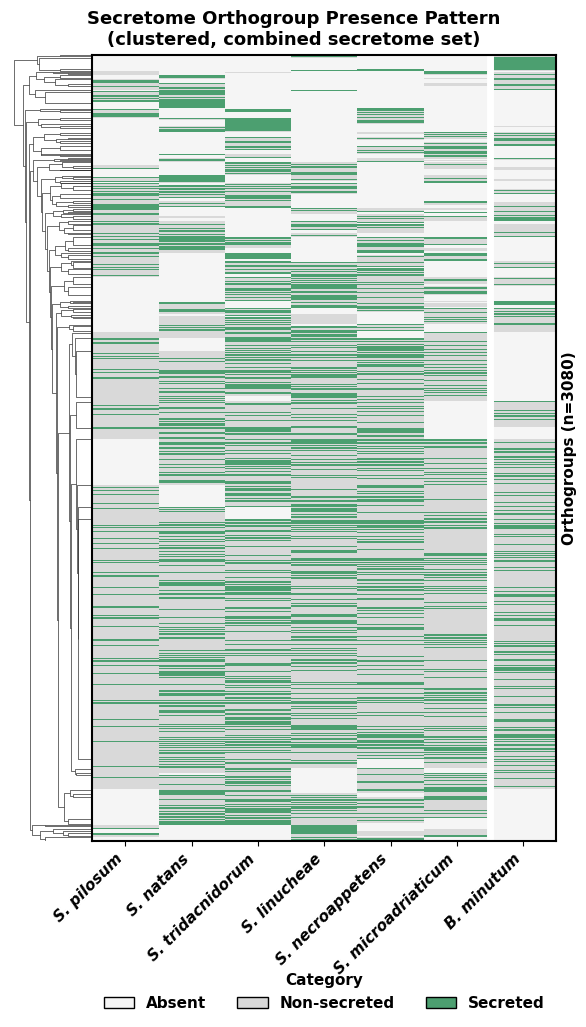

In [ ]:
# ============================================================
# Detailed orthogroup heatmap: clustered presence/absence pattern
# across strains, 3-state coding (absent / non-secreted / secreted)
# - SP+ and SP- collapsed into a single "secreted" state, matching
# the manuscript's current framing. Colors aligned with the
# green/gray scheme used in Panels A-C for visual consistency
# across the whole figure set.
# ============================================================

import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib as mpl
from matplotlib.colors import ListedColormap
from matplotlib.patches import Patch
import seaborn as sns

mpl.rcParams['font.weight'] = 'bold'
mpl.rcParams['axes.labelweight'] = 'bold'
mpl.rcParams['pdf.fonttype'] = 42
mpl.rcParams['font.size'] = 11

STRAINS = ["Spil", "Snat", "Stri", "Slin", "Snec", "Smic_jgi", "Bmin"]
SPECIES_NAMES = {
    "Spil": "S. pilosum", "Snat": "S. natans", "Stri": "S. tridacnidorum",
    "Slin": "S. linucheae", "Snec": "S. necroappetens",
    "Smic_jgi": "S. microadriaticum", "Bmin": "B. minutum",
}

# 3-state color scheme - aligned with Panel A/B/C's CATEGORY_COLORS
STATE_COLORS = {
    0: "#F5F5F5",   # absent - near white
    1: "#D9D9D9",   # non-secreted - same gray as "Non-secretome only"
    2: "#4C9F70",   # secreted (SP+ or SP-) - same green as "Secretome only"
}
STATE_LABELS = {0: "Absent", 1: "Non-secreted", 2: "Secreted"}
cmap = ListedColormap([STATE_COLORS[i] for i in range(3)])

WIDE_TSV = os.path.join(OUTPUT_DIR, "orthogroup_secretome_tagging_wide.tsv")
FIG_DIR = os.path.join(base, "Publication", "figures_pre")
os.makedirs(FIG_DIR, exist_ok=True)

wide = pd.read_csv(WIDE_TSV, sep="\t")

# ============================================================
# Build 3-state matrix, restricted to orthogroups with >=1 secreted member
# ============================================================
def encode_state(cell):
    s = str(cell)
    if "SP+" in s or "SP-" in s:
        return 2  # secreted (either SP+ or SP-)
    elif s == "not_secreted":
        return 1
    else:  # 'absent'
        return 0

state_matrix = wide[STRAINS].map(encode_state)
state_matrix.index = wide["orthogroup"]

has_secreted = (state_matrix == 2).any(axis=1)
state_matrix = state_matrix[has_secreted]
print(f"[CHECK] Heatmap includes {state_matrix.shape[0]} orthogroups with >=1 secreted member")

display_matrix = state_matrix.rename(columns=SPECIES_NAMES)

# ============================================================
# Clustered heatmap (rows clustered, columns fixed order)
# ============================================================
g = sns.clustermap(
    display_matrix,
    row_cluster=True,
    col_cluster=False,
    metric="jaccard",  # more appropriate than default Euclidean for categorical
                       # presence/absence data - doesn't reward shared absence
                       # as "similarity", which Euclidean/Hamming would
    cmap=cmap,
    vmin=0, vmax=2,
    yticklabels=False,
    xticklabels=True,
    cbar_pos=None,
    figsize=(6, 10),
    dendrogram_ratio=(0.15, 0.01),
)

for lbl in g.ax_heatmap.get_xticklabels():
    lbl.set_fontstyle("italic")
    lbl.set_fontweight("bold")
    lbl.set_rotation(45)
    lbl.set_ha("right")

g.ax_heatmap.set_ylabel(f"Orthogroups (n={state_matrix.shape[0]})", fontweight="bold")
g.ax_heatmap.set_xlabel("")

g.ax_heatmap.axvline(x=6, color="white", linewidth=5)

for spine in g.ax_heatmap.spines.values():
    spine.set_visible(True)
    spine.set_linewidth(1.5)

legend_elements = [Patch(facecolor=STATE_COLORS[i], edgecolor="black", label=STATE_LABELS[i])
                    for i in range(3)]
g.ax_heatmap.legend(handles=legend_elements, loc="upper center", bbox_to_anchor=(0.5, -0.15),
                     frameon=False, ncol=3, title="Category", title_fontproperties={"weight": "bold"})

g.fig.suptitle("Secretome Orthogroup Presence Pattern\n(clustered, combined secretome set)",
               fontweight="bold", fontsize=13, y=1.02)

for ext in ["pdf", "svg", "png"]:
    kwargs = {"dpi": 600} if ext == "png" else {}
    outpath = os.path.join(FIG_DIR, f"secretome_orthogroup_heatmap.{ext}")
    g.savefig(outpath, bbox_inches="tight", **kwargs)
    print(f"[SAVED] {outpath}")

plt.show()

[CHECK] Heatmap includes 3080 orthogroups with >=1 secreted member


/usr/local/lib/python3.12/dist-packages/seaborn/matrix.py:560: UserWarning: Clustering large matrix with scipy. Installing `fastcluster` may give better performance.
  warnings.warn(msg)


[SAVED] /content/drive/MyDrive/UTokyo/Proteome/Publication/figures_pre/secretome_orthogroup_heatmap.pdf
[SAVED] /content/drive/MyDrive/UTokyo/Proteome/Publication/figures_pre/secretome_orthogroup_heatmap.svg
[SAVED] /content/drive/MyDrive/UTokyo/Proteome/Publication/figures_pre/secretome_orthogroup_heatmap.png


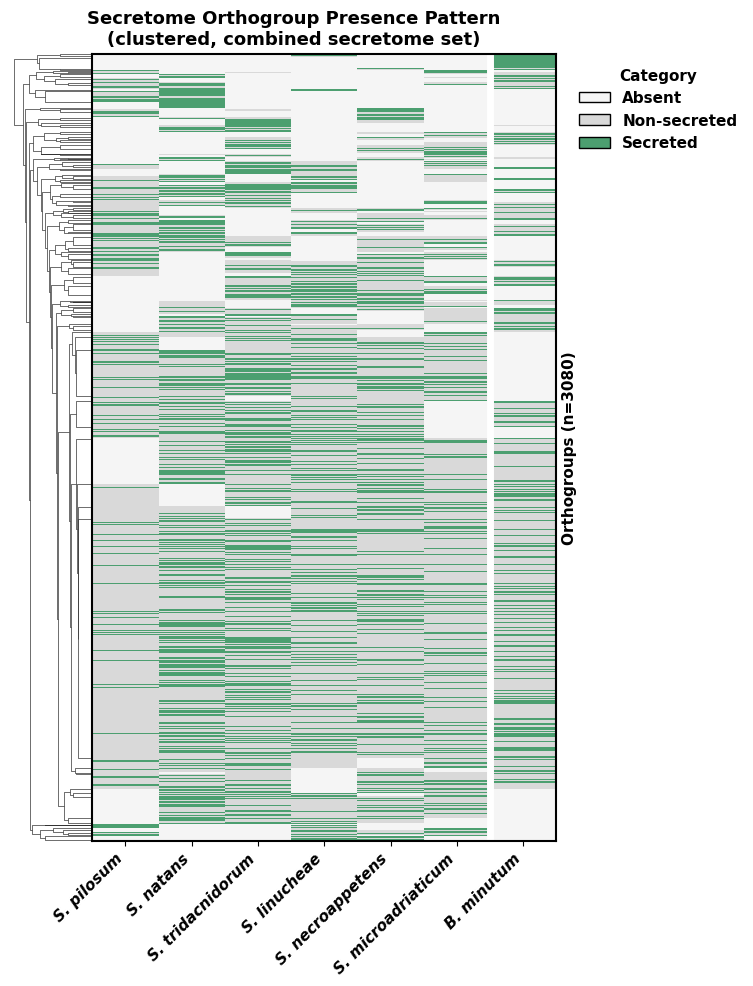

In [ ]:
# ============================================================
# Detailed orthogroup heatmap: clustered presence/absence pattern
# across strains, 3-state coding (absent / non-secreted / secreted)
# - SP+ and SP- collapsed into a single "secreted" state, matching
# the manuscript's current framing. Colors aligned with the
# green/gray scheme used in Panels A-C for visual consistency
# across the whole figure set.
# ============================================================

import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib as mpl
from matplotlib.colors import ListedColormap
from matplotlib.patches import Patch
import seaborn as sns

mpl.rcParams['font.weight'] = 'bold'
mpl.rcParams['axes.labelweight'] = 'bold'
mpl.rcParams['pdf.fonttype'] = 42
mpl.rcParams['font.size'] = 11

STRAINS = ["Spil", "Snat", "Stri", "Slin", "Snec", "Smic_jgi", "Bmin"]
SPECIES_NAMES = {
    "Spil": "S. pilosum", "Snat": "S. natans", "Stri": "S. tridacnidorum",
    "Slin": "S. linucheae", "Snec": "S. necroappetens",
    "Smic_jgi": "S. microadriaticum", "Bmin": "B. minutum",
}

# 3-state color scheme - aligned with Panel A/B/C's CATEGORY_COLORS
STATE_COLORS = {
    0: "#F5F5F5",   # absent - near white
    1: "#D9D9D9",   # non-secreted - same gray as "Non-secretome only"
    2: "#4C9F70",   # secreted (SP+ or SP-) - same green as "Secretome only"
}
STATE_LABELS = {0: "Absent", 1: "Non-secreted", 2: "Secreted"}
cmap = ListedColormap([STATE_COLORS[i] for i in range(3)])

WIDE_TSV = os.path.join(OUTPUT_DIR, "orthogroup_secretome_tagging_wide.tsv")
FIG_DIR = os.path.join(base, "Publication", "figures_pre")
os.makedirs(FIG_DIR, exist_ok=True)

wide = pd.read_csv(WIDE_TSV, sep="\t")

# ============================================================
# Build 3-state matrix, restricted to orthogroups with >=1 secreted member
# ============================================================
def encode_state(cell):
    s = str(cell)
    if "SP+" in s or "SP-" in s:
        return 2  # secreted (either SP+ or SP-)
    elif s == "not_secreted":
        return 1
    else:  # 'absent'
        return 0

state_matrix = wide[STRAINS].map(encode_state)
state_matrix.index = wide["orthogroup"]

has_secreted = (state_matrix == 2).any(axis=1)
state_matrix = state_matrix[has_secreted]
print(f"[CHECK] Heatmap includes {state_matrix.shape[0]} orthogroups with >=1 secreted member")

display_matrix = state_matrix.rename(columns=SPECIES_NAMES)

# ============================================================
# Clustered heatmap (rows clustered, columns fixed order)
# ============================================================
g = sns.clustermap(
    display_matrix,
    row_cluster=True,
    col_cluster=False,
    metric="jaccard",  # more appropriate than default Euclidean for categorical
                       # presence/absence data - doesn't reward shared absence
                       # as "similarity", which Euclidean/Hamming would
    cmap=cmap,
    vmin=0, vmax=2,
    yticklabels=False,
    xticklabels=True,
    cbar_pos=None,
    figsize=(6, 10),
    dendrogram_ratio=(0.15, 0.01),
)

for lbl in g.ax_heatmap.get_xticklabels():
    lbl.set_fontstyle("italic")
    lbl.set_fontweight("bold")
    lbl.set_rotation(45)
    lbl.set_ha("right")

g.ax_heatmap.set_ylabel(f"Orthogroups (n={state_matrix.shape[0]})", fontweight="bold")
g.ax_heatmap.set_xlabel("")

g.ax_heatmap.axvline(x=6, color="white", linewidth=5)

for spine in g.ax_heatmap.spines.values():
    spine.set_visible(True)
    spine.set_linewidth(1.5)

legend_elements = [Patch(facecolor=STATE_COLORS[i], edgecolor="black", label=STATE_LABELS[i])
                    for i in range(3)]
g.ax_heatmap.legend(handles=legend_elements, loc="upper left", bbox_to_anchor=(1.02, 1.0),
                     frameon=False, title="Category", title_fontproperties={"weight": "bold"})

g.fig.suptitle("Secretome Orthogroup Presence Pattern\n(clustered, combined secretome set)",
               fontweight="bold", fontsize=13, y=1.02)

for ext in ["pdf", "svg", "png"]:
    kwargs = {"dpi": 600} if ext == "png" else {}
    outpath = os.path.join(FIG_DIR, f"secretome_orthogroup_heatmap.{ext}")
    g.savefig(outpath, bbox_inches="tight", **kwargs)
    print(f"[SAVED] {outpath}")

plt.show()

# Strain jaccard heatmaps

[CHECK] Secretome only: 135 orthogroups
[CHECK] Non-secretome only: 27,764 orthogroups
[CHECK] Mixed: 2,945 orthogroups

[CHECK] Jaccard similarity matrices:

Secretome only:
           Spil   Snat   Stri   Slin   Snec  Smic_jgi   Bmin
Spil      1.000  0.219  0.221  0.112  0.226     0.214  0.062
Snat      0.219  1.000  0.275  0.190  0.140     0.162  0.145
Stri      0.221  0.275  1.000  0.365  0.398     0.218  0.105
Slin      0.112  0.190  0.365  1.000  0.390     0.179  0.129
Snec      0.226  0.140  0.398  0.390  1.000     0.329  0.107
Smic_jgi  0.214  0.162  0.218  0.179  0.329     1.000  0.074
Bmin      0.062  0.145  0.105  0.129  0.107     0.074  1.000

Non-secretome only:
           Spil   Snat   Stri   Slin   Snec  Smic_jgi   Bmin
Spil      1.000  0.535  0.523  0.506  0.550     0.459  0.485
Snat      0.535  1.000  0.571  0.542  0.532     0.498  0.514
Stri      0.523  0.571  1.000  0.604  0.590     0.573  0.504
Slin      0.506  0.542  0.604  1.000  0.581     0.542  0.491
Snec      0

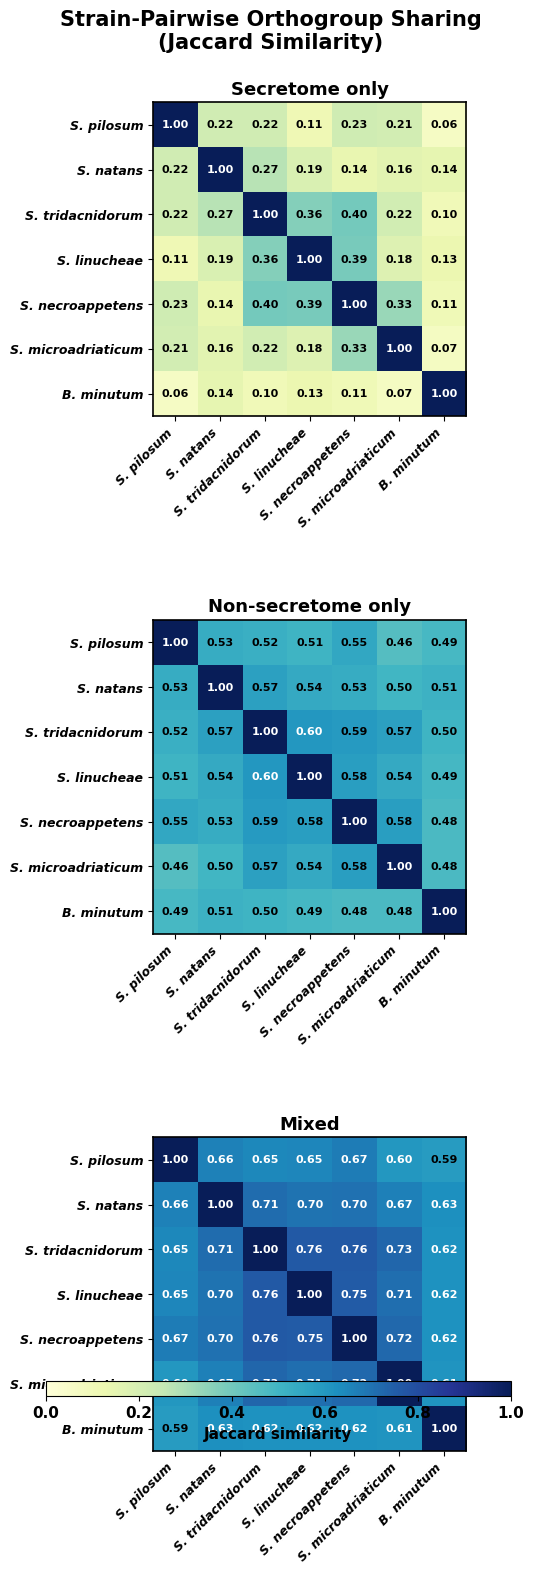

In [ ]:
# ============================================================
# Strain-by-strain Jaccard similarity heatmaps (7x7), one each for
# Secretome only / Non-secretome only / Mixed - the
# same mutually-exclusive category scheme used in Panels A-C, not
# the looser "any status present" groups used previously. Answers:
# "given orthogroups of this category, how similarly do strain
# pairs share membership in them?"
#
# Presence = strain has >=1 gene in the orthogroup (any secretion
# status), restricted to whichever category is being evaluated.
# ============================================================

import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib as mpl

mpl.rcParams['font.weight'] = 'bold'
mpl.rcParams['axes.labelweight'] = 'bold'
mpl.rcParams['pdf.fonttype'] = 42
mpl.rcParams['font.size'] = 11

STRAINS = ["Spil", "Snat", "Stri", "Slin", "Snec", "Smic_jgi", "Bmin"]
SPECIES_NAMES = {
    "Spil": "S. pilosum", "Snat": "S. natans", "Stri": "S. tridacnidorum",
    "Slin": "S. linucheae", "Snec": "S. necroappetens",
    "Smic_jgi": "S. microadriaticum", "Bmin": "B. minutum",
}

WIDE_TSV = os.path.join(OUTPUT_DIR, "orthogroup_secretome_tagging_wide.tsv")
FIG_DIR = os.path.join(base, "Publication", "figures_pre")
os.makedirs(FIG_DIR, exist_ok=True)

wide = pd.read_csv(WIDE_TSV, sep="\t")

# ============================================================
# Same per-strain status columns and group definitions as Panel B
# ============================================================
for strain in STRAINS:
    values = wide[strain].fillna("absent").astype(str).str.strip()
    wide[f"{strain}_SPpos"] = values.str.contains(r"(?:^|;)SP\+(?:;|$)", regex=True, na=False)
    wide[f"{strain}_SPneg"] = values.str.contains(r"(?:^|;)SP\-(?:;|$)", regex=True, na=False)
    wide[f"{strain}_secretome"] = wide[f"{strain}_SPpos"] | wide[f"{strain}_SPneg"]
    wide[f"{strain}_nonsecretome"] = values.str.contains(r"(?:^|;)not_secreted(?:;|$)", regex=True, na=False)
    wide[f"{strain}_whole"] = values.ne("absent")

def get_group_orthogroups(suffix):
    cols = [f"{s}_{suffix}" for s in STRAINS]
    return wide[wide[cols].any(axis=1)]

secretome_any = wide[[f"{s}_secretome" for s in STRAINS]].any(axis=1)
nonsecretome_any = wide[[f"{s}_nonsecretome" for s in STRAINS]].any(axis=1)

wide["category"] = "Mixed"
wide.loc[secretome_any & ~nonsecretome_any, "category"] = "Secretome only"
wide.loc[nonsecretome_any & ~secretome_any, "category"] = "Non-secretome only"

groups = {
    "Secretome only": wide[wide["category"] == "Secretome only"],
    "Non-secretome only": wide[wide["category"] == "Non-secretome only"],
    "Mixed": wide[wide["category"] == "Mixed"],
}

for name, df in groups.items():
    print(f"[CHECK] {name}: {df.shape[0]:,} orthogroups")

# ============================================================
# Pairwise Jaccard similarity between strains, within each group
# ============================================================
def jaccard_matrix(df):
    presence = df[[f"{s}_whole" for s in STRAINS]].to_numpy()
    n = len(STRAINS)
    sim = np.zeros((n, n))
    for i in range(n):
        for j in range(n):
            a, b = presence[:, i], presence[:, j]
            union = np.sum(a | b)
            intersect = np.sum(a & b)
            sim[i, j] = intersect / union if union > 0 else np.nan
    return pd.DataFrame(sim, index=STRAINS, columns=STRAINS)

jaccard_results = {name: jaccard_matrix(df) for name, df in groups.items()}

print("\n[CHECK] Jaccard similarity matrices:")
for name, mat in jaccard_results.items():
    print(f"\n{name}:")
    print(mat.round(3))

# ============================================================
# Plot - 3 side-by-side heatmaps, shared strain order and color scale
# ============================================================
plt.close("all")
fig, axes = plt.subplots(3, 1, figsize=(6, 15.5))

display_labels = [SPECIES_NAMES[s] for s in STRAINS]

for ax, (name, mat) in zip(axes, jaccard_results.items()):
    im = ax.imshow(mat.values, vmin=0, vmax=1, cmap="YlGnBu")
    ax.set_xticks(range(len(STRAINS)))
    ax.set_yticks(range(len(STRAINS)))
    ax.set_xticklabels(display_labels, rotation=45, ha="right", fontstyle="italic", fontsize=9)
    ax.set_yticklabels(display_labels, fontstyle="italic", fontsize=9)
    ax.set_title(name, fontweight="bold", fontsize=13)

    for i in range(len(STRAINS)):
        for j in range(len(STRAINS)):
            val = mat.values[i, j]
            color = "white" if val > 0.6 else "black"
            ax.text(j, i, f"{val:.2f}", ha="center", va="center", fontsize=8,
                     fontweight="bold", color=color)

    for spine in ax.spines.values():
        spine.set_visible(True)
        spine.set_linewidth(1.2)

cbar = fig.colorbar(im, ax=axes, orientation="horizontal", location="bottom",
                     fraction=0.02, pad=0.04, aspect=30)
cbar.set_label("Jaccard similarity", fontweight="bold", fontsize=11)

fig.suptitle("Strain-Pairwise Orthogroup Sharing\n(Jaccard Similarity)", fontweight="bold", fontsize=15, y=1.01)

plt.subplots_adjust(left=0.18, right=0.95, top=0.95, bottom=0.08, hspace=0.65)

for ext in ["pdf", "svg", "png"]:
    kwargs = {"dpi": 600} if ext == "png" else {}
    outpath = os.path.join(FIG_DIR, f"strain_jaccard_similarity.{ext}")
    fig.savefig(outpath, bbox_inches="tight", **kwargs)
    print(f"[SAVED] {outpath}")

plt.show()